In [4]:
from pathlib import Path
import sys

# Find the project root
PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "src").exists():

    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError(
            "Could not find project root."
        )

    PROJECT_ROOT = PROJECT_ROOT.parent

# Add project root to Python path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)
print("Python path configured successfully.")

Project root: /Users/debarghamishra/Downloads/Agentic_process_Intelligence
Python path configured successfully.


In [5]:
from src.data.data_loader import load_all

from src.analytics.process_analytics import (
    build_event_object,
    get_pr_events,
    get_po_events,
    get_invoice_events,
    calculate_activity_duration,
    calculate_transition_statistics,
    calculate_pr_cycle_time,
    calculate_pr_approval_time,
    calculate_rejection_metrics,
    calculate_match_metrics,
    generate_process_kpis
)

print("Imports successful!")

Imports successful!


In [6]:
events, relations, objects = load_all()

print("Events:", events.shape)
print("Relations:", relations.shape)
print("Objects:", objects.shape)

Looking for database at:
/Users/debarghamishra/Downloads/Agentic_process_Intelligence/data/lrms_02_p2p.sqlite
Events: (8300, 6)
Relations: (16827, 6)
Objects: (4493, 13)


In [7]:
event_object = build_event_object(
    events,
    relations
)

print(event_object.shape)

event_object.head()

(16827, 8)


,ocel:eid,ocel:oid,ocel:type,user,cost_center,ocel:activity,ocel:timestamp,location
0,E264,PR31,Purchase Requisition,User17,CC11,Create PR,2024-09-02 08:04:53+00:00,NaN
1,E531,PR63,Purchase Requisition,User42,CC15,Create PR,2024-09-02 08:04:53+00:00,NaN
2,E2244,PR272,Purchase Requisition,User31,CC9,Create PR,2024-09-02 08:04:54+00:00,NaN
3,E2280,PR276,Purchase Requisition,User43,CC16,Create PR,2024-09-02 08:04:54+00:00,NaN
4,E2504,PR304,Purchase Requisition,User17,CC6,Create PR,2024-09-02 08:04:54+00:00,NaN


In [8]:
event_object = build_event_object(
    events,
    relations
)

print("Event-object shape:", event_object.shape)

event_object.head()

Event-object shape: (16827, 8)


,ocel:eid,ocel:oid,ocel:type,user,cost_center,ocel:activity,ocel:timestamp,location
0,E264,PR31,Purchase Requisition,User17,CC11,Create PR,2024-09-02 08:04:53+00:00,NaN
1,E531,PR63,Purchase Requisition,User42,CC15,Create PR,2024-09-02 08:04:53+00:00,NaN
2,E2244,PR272,Purchase Requisition,User31,CC9,Create PR,2024-09-02 08:04:54+00:00,NaN
3,E2280,PR276,Purchase Requisition,User43,CC16,Create PR,2024-09-02 08:04:54+00:00,NaN
4,E2504,PR304,Purchase Requisition,User17,CC6,Create PR,2024-09-02 08:04:54+00:00,NaN


In [9]:
event_object.columns.tolist()

['ocel:eid',
 'ocel:oid',
 'ocel:type',
 'user',
 'cost_center',
 'ocel:activity',
 'ocel:timestamp',
 'location']

In [10]:
pr_events = get_pr_events(
    event_object
)

print("PR event records:", len(pr_events))

pr_events.head(20)

PR event records: 4227


,ocel:eid,ocel:oid,ocel:type,user,cost_center,ocel:activity,ocel:timestamp,location
0,E264,PR31,Purchase Requisition,User17,CC11,Create PR,2024-09-02 08:04:53+00:00,NaN
1,E531,PR63,Purchase Requisition,User42,CC15,Create PR,2024-09-02 08:04:53+00:00,NaN
2,E2244,PR272,Purchase Requisition,User31,CC9,Create PR,2024-09-02 08:04:54+00:00,NaN
3,E2280,PR276,Purchase Requisition,User43,CC16,Create PR,2024-09-02 08:04:54+00:00,NaN
4,E2504,PR304,Purchase Requisition,User17,CC6,Create PR,2024-09-02 08:04:54+00:00,NaN
5,E2598,PR316,Purchase Requisition,User34,CC20,Create PR,2024-09-02 08:04:54+00:00,NaN
6,E2796,PR338,Purchase Requisition,User18,CC19,Create PR,2024-09-02 08:04:54+00:00,NaN
7,E4127,PR496,Purchase Requisition,User35,CC18,Create PR,2024-09-02 08:04:55+00:00,NaN
8,E4230,PR509,Purchase Requisition,User16,CC3,Create PR,2024-09-02 08:04:55+00:00,NaN
9,E6297,PR762,Purchase Requisition,User19,CC3,Create PR,2024-09-02 08:04:56+00:00,NaN


In [11]:
pr_events[
    [
        "ocel:oid",
        "ocel:activity",
        "ocel:timestamp"
    ]
].head(20)

,ocel:oid,ocel:activity,ocel:timestamp
0,PR31,Create PR,2024-09-02 08:04:53+00:00
1,PR63,Create PR,2024-09-02 08:04:53+00:00
2,PR272,Create PR,2024-09-02 08:04:54+00:00
3,PR276,Create PR,2024-09-02 08:04:54+00:00
4,PR304,Create PR,2024-09-02 08:04:54+00:00
5,PR316,Create PR,2024-09-02 08:04:54+00:00
6,PR338,Create PR,2024-09-02 08:04:54+00:00
7,PR496,Create PR,2024-09-02 08:04:55+00:00
8,PR509,Create PR,2024-09-02 08:04:55+00:00
9,PR762,Create PR,2024-09-02 08:04:56+00:00


In [12]:
pr_transitions = calculate_transition_statistics(
    pr_events
)

pr_transitions

,previous_activity,ocel:activity,occurrences,average_hours,median_hours,p90_hours,max_hours
11,Reject PR,Create PO (Batch),67,0.557235,0.499444,1.150000,1.816667
2,Create PO,Create PO (Batch),195,0.478343,0.399444,1.016833,2.033333
8,Create PR,Approve PR,732,0.468670,0.433333,0.883333,1.000000
0,Approve PR,Create PO,302,0.461810,0.433333,0.865000,1.000000
9,Create PR,Create PO (Batch),188,0.421475,0.416111,0.755472,0.949722
1,Approve PR,Create PO (Batch),598,0.402063,0.350000,0.850000,1.000000
10,Create PR,Reject PR,80,0.401667,0.341667,0.835000,1.000000
5,Create PO (Batch),Create PO (Batch),682,0.350751,0.266944,0.767194,1.633889
4,Create PO (Batch),Create PO,141,0.293002,0.233611,0.633056,0.983333
7,Create PO (Batch),Reject PR,20,0.288417,0.192083,0.755306,0.833056


In [13]:
pr_cycle_time = calculate_pr_cycle_time(
    pr_events
)

pr_cycle_time.head()

,ocel:oid,start_time,end_time,cycle_time_hours
0,PR1,2024-09-02 08:10:53+00:00,2024-09-02 10:03:56+00:00,1.884167
1,PR10,2024-09-02 08:41:53+00:00,2024-09-02 09:44:53+00:00,1.050000
2,PR100,2024-09-02 08:07:53+00:00,2024-09-02 09:30:53+00:00,1.383333
3,PR1000,2024-09-02 08:10:57+00:00,2024-09-02 09:39:57+00:00,1.483333
4,PR101,2024-09-02 08:27:53+00:00,2024-09-02 10:06:53+00:00,1.650000


In [14]:
pr_cycle_time["cycle_time_hours"].describe()

count    1000.000000
mean        1.301219
std         0.480886
min         0.016667
25%         0.983333
50%         1.299722
75%         1.633403
max         2.983611
Name: cycle_time_hours, dtype: float64

In [15]:
approval_analysis = calculate_pr_approval_time(
    pr_events
)

approval_analysis.head()

,ocel:oid,create_time,approve_time,reject_time,approval_time_hours,rejection_time_hours
0,PR1,2024-09-02 08:10:53+00:00,2024-09-02 08:53:53+00:00,NaT,0.716667,NaN
1,PR10,2024-09-02 08:41:53+00:00,2024-09-02 09:19:53+00:00,NaT,0.633333,NaN
2,PR100,2024-09-02 08:07:53+00:00,2024-09-02 08:50:53+00:00,NaT,0.716667,NaN
3,PR1000,2024-09-02 08:10:57+00:00,2024-09-02 08:51:57+00:00,NaT,0.683333,NaN
4,PR101,2024-09-02 08:27:53+00:00,2024-09-02 09:15:53+00:00,NaT,0.800000,NaN


In [16]:
rejection_metrics = calculate_rejection_metrics(
    pr_events
)

rejection_metrics

{'created_prs': 1000,
 'approved_prs': 900,
 'rejected_prs': 100,
 'approval_rate': 90.0,
 'rejection_rate': 10.0}

In [17]:
match_metrics = calculate_match_metrics(
    events
)

match_metrics

{'total_matches': 900,
 'successful_matches': 823,
 'mismatches': 77,
 'success_rate': 91.44444444444444,
 'mismatch_rate': 8.555555555555555}

In [18]:
kpis = generate_process_kpis(
    events,
    pr_events
)

kpis

{'total_prs': 1000,
 'approved_prs': 900,
 'rejected_prs': 100,
 'approval_rate': 90.0,
 'rejection_rate': 10.0,
 'average_cycle_time_hours': np.float64(1.3012191666666668),
 'median_cycle_time_hours': np.float64(1.2997222222222222),
 'p90_cycle_time_hours': np.float64(1.8664166666666666),
 'three_way_match_success_rate': 91.44444444444444,
 'three_way_match_mismatch_rate': 8.555555555555555}

In [19]:
print("Event-object relationships:")
print(
    relations[
        ["ocel:eid", "ocel:oid", "ocel:type"]
    ].head(20)
)

Event-object relationships:
   ocel:eid ocel:oid             ocel:type
0      E264     PR31  Purchase Requisition
1      E531     PR63  Purchase Requisition
2     E2244    PR272  Purchase Requisition
3     E2280    PR276  Purchase Requisition
4     E2504    PR304  Purchase Requisition
5     E2598    PR316  Purchase Requisition
6     E2796    PR338  Purchase Requisition
7     E4127    PR496  Purchase Requisition
8     E4230    PR509  Purchase Requisition
9     E6297    PR762  Purchase Requisition
10    E6335    PR767  Purchase Requisition
11    E7331    PR887  Purchase Requisition
12    E8016    PR967  Purchase Requisition
13     E612     PR72  Purchase Requisition
14     E666     PR78  Purchase Requisition
15    E1056    PR126  Purchase Requisition
16    E1848    PR221  Purchase Requisition
17    E1902    PR227  Purchase Requisition
18    E2042    PR248  Purchase Requisition
19    E2392    PR290  Purchase Requisition


In [21]:
import sqlite3
import pandas as pd

from src.data.data_loader import DB_PATH

conn = sqlite3.connect(DB_PATH)

object_object = pd.read_sql_query(
    "SELECT * FROM object_object",
    conn
)

conn.close()

object_object.head(20)

,ocel_source_id,ocel_target_id,ocel_qualifier


In [23]:
object_object.columns.tolist()

['ocel_source_id', 'ocel_target_id', 'ocel_qualifier']

In [24]:
print("Shape:", object_object.shape)

print("\nColumns:")
print(object_object.columns.tolist())

print("\nFirst 20 relationships:")
display(object_object.head(20))

Shape: (0, 3)

Columns:
['ocel_source_id', 'ocel_target_id', 'ocel_qualifier']

First 20 relationships:


,ocel_source_id,ocel_target_id,ocel_qualifier


In [25]:
print("Relationship qualifiers:")
print(
    object_object["ocel_qualifier"].value_counts()
)

Relationship qualifiers:
Series([], Name: count, dtype: int64)


In [26]:
print("Source → Target relationships:")
print(
    object_object[
        [
            "ocel_source_id",
            "ocel_target_id",
            "ocel_qualifier"
        ]
    ].head(30)
)

Source → Target relationships:
Empty DataFrame
Columns: [ocel_source_id, ocel_target_id, ocel_qualifier]
Index: []


In [27]:
source_objects = objects[
    ["ocel:oid", "ocel:type"]
].rename(
    columns={
        "ocel:oid": "ocel_source_id",
        "ocel:type": "source_type"
    }
)

target_objects = objects[
    ["ocel:oid", "ocel:type"]
].rename(
    columns={
        "ocel:oid": "ocel_target_id",
        "ocel:type": "target_type"
    }
)

object_relationships = (
    object_object
    .merge(
        source_objects,
        on="ocel_source_id",
        how="left"
    )
    .merge(
        target_objects,
        on="ocel_target_id",
        how="left"
    )
)

object_relationships.head(20)

,ocel_source_id,ocel_target_id,ocel_qualifier,source_type,target_type


In [28]:
relationship_summary = (
    object_relationships
    [
        [
            "source_type",
            "target_type",
            "ocel_qualifier"
        ]
    ]
    .value_counts()
    .reset_index(name="count")
)

relationship_summary

,source_type,target_type,ocel_qualifier,count


In [30]:
object_object.columns.tolist()


['ocel_source_id', 'ocel_target_id', 'ocel_qualifier']

In [31]:
object_object.shape

(0, 3)

In [32]:
object_object.head(30)

,ocel_source_id,ocel_target_id,ocel_qualifier


In [33]:
import sqlite3
import pandas as pd

from src.data.data_loader import DB_PATH

conn = sqlite3.connect(DB_PATH)

object_object = pd.read_sql_query(
    "SELECT * FROM object_object",
    conn
)

conn.close()

print("Shape:", object_object.shape)
print("Columns:", object_object.columns.tolist())

display(object_object.head(20))

Shape: (0, 3)
Columns: ['ocel_source_id', 'ocel_target_id', 'ocel_qualifier']


,ocel_source_id,ocel_target_id,ocel_qualifier


In [34]:
object_object["ocel_qualifier"].value_counts()

Series([], Name: count, dtype: int64)

In [35]:
source_objects = objects[
    ["ocel:oid", "ocel:type"]
].rename(
    columns={
        "ocel:oid": "ocel_source_id",
        "ocel:type": "source_type"
    }
)

target_objects = objects[
    ["ocel:oid", "ocel:type"]
].rename(
    columns={
        "ocel:oid": "ocel_target_id",
        "ocel:type": "target_type"
    }
)

object_relationships = (
    object_object
    .merge(
        source_objects,
        on="ocel_source_id",
        how="left"
    )
    .merge(
        target_objects,
        on="ocel_target_id",
        how="left"
    )
)

print("Relationship records:", len(object_relationships))

display(object_relationships.head(20))

Relationship records: 0


,ocel_source_id,ocel_target_id,ocel_qualifier,source_type,target_type


In [36]:
relationship_summary = (
    object_relationships[
        [
            "source_type",
            "target_type",
            "ocel_qualifier"
        ]
    ]
    .value_counts()
    .reset_index(name="count")
)

relationship_summary

,source_type,target_type,ocel_qualifier,count


In [37]:
# ============================================================
# DERIVE OBJECT-TO-OBJECT RELATIONSHIPS FROM EVENT RELATIONS
# ============================================================

event_objects = relations[
    [
        "ocel:eid",
        "ocel:oid",
        "ocel:type"
    ]
].copy()

# Objects participating in the same event
derived_object_relationships = (
    event_objects
    .merge(
        event_objects,
        on="ocel:eid",
        suffixes=("_source", "_target")
    )
)

# Remove self relationships
derived_object_relationships = (
    derived_object_relationships[
        derived_object_relationships["ocel:oid_source"]
        !=
        derived_object_relationships["ocel:oid_target"]
    ]
)

print(
    "Derived relationships:",
    len(derived_object_relationships)
)

display(
    derived_object_relationships.head(30)
)

Derived relationships: 26744


,ocel:eid,ocel:oid_source,ocel:type_source,ocel:oid_target,ocel:type_target
292,E311,PR630,Purchase Requisition,PR961,Purchase Requisition
293,E311,PR630,Purchase Requisition,PR36,Purchase Requisition
294,E311,PR630,Purchase Requisition,PO6416,Purchase Order
295,E311,PR961,Purchase Requisition,PR630,Purchase Requisition
297,E311,PR961,Purchase Requisition,PR36,Purchase Requisition
298,E311,PR961,Purchase Requisition,PO6416,Purchase Order
299,E311,PR36,Purchase Requisition,PR630,Purchase Requisition
300,E311,PR36,Purchase Requisition,PR961,Purchase Requisition
302,E311,PR36,Purchase Requisition,PO6416,Purchase Order
303,E311,PO6416,Purchase Order,PR630,Purchase Requisition


In [38]:
object_pair_summary = (
    derived_object_relationships[
        [
            "ocel:type_source",
            "ocel:type_target"
        ]
    ]
    .value_counts()
    .reset_index(name="count")
)

object_pair_summary

,ocel:type_source,ocel:type_target,count
0,Purchase Requisition,Purchase Requisition,6090
1,Purchase Requisition,Purchase Order,2227
2,Purchase Order,Purchase Requisition,2227
3,Purchase Order,Goods Receipt,1800
4,Goods Receipt,Purchase Order,1800
5,Purchase Order,Invoice,1800
6,Invoice,Purchase Order,1800
7,Purchase Order,Supplier,900
8,Supplier,Purchase Order,900
9,Goods Receipt,Invoice,900


In [39]:
derived_object_relationships = (
    relations[
        ["ocel:eid", "ocel:oid", "ocel:type"]
    ]
    .merge(
        relations[
            ["ocel:eid", "ocel:oid", "ocel:type"]
        ],
        on="ocel:eid",
        suffixes=("_source", "_target")
    )
)

derived_object_relationships = (
    derived_object_relationships[
        derived_object_relationships["ocel:oid_source"]
        !=
        derived_object_relationships["ocel:oid_target"]
    ]
)

print(
    "Derived relationships:",
    len(derived_object_relationships)
)

display(derived_object_relationships.head(30))

Derived relationships: 26744


,ocel:eid,ocel:oid_source,ocel:type_source,ocel:oid_target,ocel:type_target
292,E311,PR630,Purchase Requisition,PR961,Purchase Requisition
293,E311,PR630,Purchase Requisition,PR36,Purchase Requisition
294,E311,PR630,Purchase Requisition,PO6416,Purchase Order
295,E311,PR961,Purchase Requisition,PR630,Purchase Requisition
297,E311,PR961,Purchase Requisition,PR36,Purchase Requisition
298,E311,PR961,Purchase Requisition,PO6416,Purchase Order
299,E311,PR36,Purchase Requisition,PR630,Purchase Requisition
300,E311,PR36,Purchase Requisition,PR961,Purchase Requisition
302,E311,PR36,Purchase Requisition,PO6416,Purchase Order
303,E311,PO6416,Purchase Order,PR630,Purchase Requisition


In [40]:
object_pair_summary = (
    derived_object_relationships[
        [
            "ocel:type_source",
            "ocel:type_target"
        ]
    ]
    .value_counts()
    .reset_index(name="count")
)

object_pair_summary

,ocel:type_source,ocel:type_target,count
0,Purchase Requisition,Purchase Requisition,6090
1,Purchase Requisition,Purchase Order,2227
2,Purchase Order,Purchase Requisition,2227
3,Purchase Order,Goods Receipt,1800
4,Goods Receipt,Purchase Order,1800
5,Purchase Order,Invoice,1800
6,Invoice,Purchase Order,1800
7,Purchase Order,Supplier,900
8,Supplier,Purchase Order,900
9,Goods Receipt,Invoice,900


In [42]:
pr_po_links = derived_object_relationships[
    (
        (derived_object_relationships["ocel:type_source"] == "Purchase Requisition") &
        (derived_object_relationships["ocel:type_target"] == "Purchase Order")
    )
    |
    (
        (derived_object_relationships["ocel:type_source"] == "Purchase Order") &
        (derived_object_relationships["ocel:type_target"] == "Purchase Requisition")
    )
].copy()

print("PR-PO co-occurrence records:", len(pr_po_links))

display(
    pr_po_links[
        [
            "ocel:eid",
            "ocel:oid_source",
            "ocel:type_source",
            "ocel:oid_target",
            "ocel:type_target"
        ]
    ].head(30)
)

PR-PO co-occurrence records: 4454


,ocel:eid,ocel:oid_source,ocel:type_source,ocel:oid_target,ocel:type_target
294,E311,PR630,Purchase Requisition,PO6416,Purchase Order
298,E311,PR961,Purchase Requisition,PO6416,Purchase Order
302,E311,PR36,Purchase Requisition,PO6416,Purchase Order
303,E311,PO6416,Purchase Order,PR630,Purchase Requisition
304,E311,PO6416,Purchase Order,PR961,Purchase Requisition
305,E311,PO6416,Purchase Order,PR36,Purchase Requisition
388,E7134,PR878,Purchase Requisition,PO8255,Purchase Order
391,E7134,PR861,Purchase Requisition,PO8255,Purchase Order
392,E7134,PO8255,Purchase Order,PR878,Purchase Requisition
393,E7134,PO8255,Purchase Order,PR861,Purchase Requisition


In [43]:
pr_po_links = pr_po_links.merge(
    events[
        [
            "ocel:eid",
            "ocel:activity",
            "ocel:timestamp"
        ]
    ],
    on="ocel:eid",
    how="left"
)

display(pr_po_links.head(30))

,ocel:eid,ocel:oid_source,ocel:type_source,ocel:oid_target,ocel:type_target,ocel:activity,ocel:timestamp
0,E311,PR630,Purchase Requisition,PO6416,Purchase Order,Create PO (Batch),2024-09-02 08:20:53+00:00
1,E311,PR961,Purchase Requisition,PO6416,Purchase Order,Create PO (Batch),2024-09-02 08:20:53+00:00
2,E311,PR36,Purchase Requisition,PO6416,Purchase Order,Create PO (Batch),2024-09-02 08:20:53+00:00
3,E311,PO6416,Purchase Order,PR630,Purchase Requisition,Create PO (Batch),2024-09-02 08:20:53+00:00
4,E311,PO6416,Purchase Order,PR961,Purchase Requisition,Create PO (Batch),2024-09-02 08:20:53+00:00
5,E311,PO6416,Purchase Order,PR36,Purchase Requisition,Create PO (Batch),2024-09-02 08:20:53+00:00
6,E7134,PR878,Purchase Requisition,PO8255,Purchase Order,Create PO (Batch),2024-09-02 08:23:57+00:00
7,E7134,PR861,Purchase Requisition,PO8255,Purchase Order,Create PO (Batch),2024-09-02 08:23:57+00:00
8,E7134,PO8255,Purchase Order,PR878,Purchase Requisition,Create PO (Batch),2024-09-02 08:23:57+00:00
9,E7134,PO8255,Purchase Order,PR861,Purchase Requisition,Create PO (Batch),2024-09-02 08:23:57+00:00


In [44]:
# Keep only one direction: Purchase Requisition -> Purchase Order
pr_po_graph = pr_po_links[
    (pr_po_links["ocel:type_source"] == "Purchase Requisition") &
    (pr_po_links["ocel:type_target"] == "Purchase Order")
].copy()

# Keep the important columns
pr_po_graph = pr_po_graph[
    [
        "ocel:eid",
        "ocel:oid_source",
        "ocel:oid_target",
        "ocel:activity",
        "ocel:timestamp"
    ]
].drop_duplicates()

# Rename for clarity
pr_po_graph = pr_po_graph.rename(
    columns={
        "ocel:oid_source": "pr_id",
        "ocel:oid_target": "po_id",
        "ocel:eid": "event_id",
        "ocel:activity": "activity",
        "ocel:timestamp": "timestamp"
    }
)

print("PR → PO relationships:", len(pr_po_graph))

display(pr_po_graph.head(30))


PR → PO relationships: 2227


,event_id,pr_id,po_id,activity,timestamp
0,E311,PR630,PO6416,Create PO (Batch),2024-09-02 08:20:53+00:00
1,E311,PR961,PO6416,Create PO (Batch),2024-09-02 08:20:53+00:00
2,E311,PR36,PO6416,Create PO (Batch),2024-09-02 08:20:53+00:00
6,E7134,PR878,PO8255,Create PO (Batch),2024-09-02 08:23:57+00:00
7,E7134,PR861,PO8255,Create PO (Batch),2024-09-02 08:23:57+00:00
10,E3700,PR446,PO289,Create PO,2024-09-02 08:25:55+00:00
12,E7194,PR870,PO586,Create PO,2024-09-02 08:25:57+00:00
14,E3051,PR370,PO2247,Create PO,2024-09-02 08:26:54+00:00
16,E8240,PR826,PO393,Create PO (Batch),2024-09-02 08:27:57+00:00
17,E8240,PR687,PO393,Create PO (Batch),2024-09-02 08:27:57+00:00


In [45]:
pr_po_graph["activity"].value_counts()

activity
Create PO (Batch)    1784
Create PO             443
Name: count, dtype: int64

In [46]:
# Keep only cross-object-type relationships
# and only one direction for each object pair

object_graph = derived_object_relationships[
    derived_object_relationships["ocel:type_source"]
    !=
    derived_object_relationships["ocel:type_target"]
].copy()

# Canonicalize the pair direction
object_graph["object_type_1"] = object_graph[
    ["ocel:type_source", "ocel:type_target"]
].min(axis=1)

object_graph["object_type_2"] = object_graph[
    ["ocel:type_source", "ocel:type_target"]
].max(axis=1)

object_graph = object_graph[
    [
        "ocel:eid",
        "ocel:oid_source",
        "ocel:oid_target",
        "ocel:type_source",
        "ocel:type_target",
        "object_type_1",
        "object_type_2"
    ]
].drop_duplicates()

print("Canonical object relationships:", len(object_graph))

display(object_graph.head(30))

Canonical object relationships: 20654


,ocel:eid,ocel:oid_source,ocel:oid_target,ocel:type_source,ocel:type_target,object_type_1,object_type_2
294,E311,PR630,PO6416,Purchase Requisition,Purchase Order,Purchase Order,Purchase Requisition
298,E311,PR961,PO6416,Purchase Requisition,Purchase Order,Purchase Order,Purchase Requisition
302,E311,PR36,PO6416,Purchase Requisition,Purchase Order,Purchase Order,Purchase Requisition
303,E311,PO6416,PR630,Purchase Order,Purchase Requisition,Purchase Order,Purchase Requisition
304,E311,PO6416,PR961,Purchase Order,Purchase Requisition,Purchase Order,Purchase Requisition
305,E311,PO6416,PR36,Purchase Order,Purchase Requisition,Purchase Order,Purchase Requisition
388,E7134,PR878,PO8255,Purchase Requisition,Purchase Order,Purchase Order,Purchase Requisition
391,E7134,PR861,PO8255,Purchase Requisition,Purchase Order,Purchase Order,Purchase Requisition
392,E7134,PO8255,PR878,Purchase Order,Purchase Requisition,Purchase Order,Purchase Requisition
393,E7134,PO8255,PR861,Purchase Order,Purchase Requisition,Purchase Order,Purchase Requisition


In [47]:
object_graph_summary = (
    object_graph[
        ["object_type_1", "object_type_2"]
    ]
    .value_counts()
    .reset_index(name="count")
)

object_graph_summary

,object_type_1,object_type_2,count
0,Purchase Order,Purchase Requisition,4454
1,Goods Receipt,Purchase Order,3600
2,Invoice,Purchase Order,3600
3,Purchase Order,Supplier,1800
4,Goods Receipt,Invoice,1800
5,Invoice,Supplier,1800
6,Invoice,Payment,1800
7,Payment,Supplier,1800


In [48]:
object_graph_clean = object_graph.drop_duplicates(
    subset=[
        "ocel:eid",
        "ocel:oid_source",
        "ocel:oid_target",
        "object_type_1",
        "object_type_2"
]
).copy()

# Remove reverse object-ID edges
object_graph_clean["object_id_1"] = object_graph_clean[
    ["ocel:oid_source", "ocel:oid_target"]
].min(axis=1)

object_graph_clean["object_id_2"] = object_graph_clean[
    ["ocel:oid_source", "ocel:oid_target"]
].max(axis=1)

object_graph_clean = object_graph_clean.drop_duplicates(
    subset=[
        "ocel:eid",
        "object_id_1",
        "object_id_2"
    ]
)

print("Clean object relationships:", len(object_graph_clean))

display(
    object_graph_clean.head(30)
)

Clean object relationships: 10327


,ocel:eid,ocel:oid_source,ocel:oid_target,ocel:type_source,ocel:type_target,object_type_1,object_type_2,object_id_1,object_id_2
294,E311,PR630,PO6416,Purchase Requisition,Purchase Order,Purchase Order,Purchase Requisition,PO6416,PR630
298,E311,PR961,PO6416,Purchase Requisition,Purchase Order,Purchase Order,Purchase Requisition,PO6416,PR961
302,E311,PR36,PO6416,Purchase Requisition,Purchase Order,Purchase Order,Purchase Requisition,PO6416,PR36
388,E7134,PR878,PO8255,Purchase Requisition,Purchase Order,Purchase Order,Purchase Requisition,PO8255,PR878
391,E7134,PR861,PO8255,Purchase Requisition,Purchase Order,Purchase Order,Purchase Requisition,PO8255,PR861
435,E3700,PR446,PO289,Purchase Requisition,Purchase Order,Purchase Order,Purchase Requisition,PO289,PR446
445,E7194,PR870,PO586,Purchase Requisition,Purchase Order,Purchase Order,Purchase Requisition,PO586,PR870
461,E3051,PR370,PO2247,Purchase Requisition,Purchase Order,Purchase Order,Purchase Requisition,PO2247,PR370
497,E8240,PR826,PO393,Purchase Requisition,Purchase Order,Purchase Order,Purchase Requisition,PO393,PR826
504,E8240,PR687,PO393,Purchase Requisition,Purchase Order,Purchase Order,Purchase Requisition,PO393,PR687


In [49]:
clean_graph_summary = (
    object_graph_clean[
        ["object_type_1", "object_type_2"]
    ]
    .value_counts()
    .reset_index(name="count")
)

clean_graph_summary

,object_type_1,object_type_2,count
0,Purchase Order,Purchase Requisition,2227
1,Goods Receipt,Purchase Order,1800
2,Invoice,Purchase Order,1800
3,Purchase Order,Supplier,900
4,Goods Receipt,Invoice,900
5,Invoice,Supplier,900
6,Invoice,Payment,900
7,Payment,Supplier,900


In [51]:
# Get all relations involving Purchase Requisition objects
pr_relations = relations[
    relations["ocel:type"] == "Purchase Requisition"
].copy()

# Join event information
pr_relations = pr_relations.merge(
    events[
        [
            "ocel:eid",
            "ocel:activity",
            "ocel:timestamp"
        ]
    ],
    on="ocel:eid",
    how="left",
    suffixes=("", "_event")
)

# Sort chronologically for each PR
pr_relations = pr_relations.sort_values(
    ["ocel:oid", "ocel:timestamp"]
)

print("PR event records:", len(pr_relations))

display(
    pr_relations[
        [
            "ocel:oid",
            "ocel:eid",
            "ocel:activity",
            "ocel:timestamp"
        ]
    ].head(30)
)

PR event records: 4227


,ocel:oid,ocel:eid,ocel:activity,ocel:timestamp
111,PR1,E1,Create PR,2024-09-02 08:10:53+00:00
1290,PR1,E2,Approve PR,2024-09-02 08:53:53+00:00
2100,PR1,E3,Create PO (Batch),2024-09-02 09:12:53+00:00
3848,PR1,E6629,Create PO (Batch),2024-09-02 10:03:56+00:00
874,PR10,E82,Create PR,2024-09-02 08:41:53+00:00
2357,PR10,E83,Approve PR,2024-09-02 09:19:53+00:00
3337,PR10,E84,Create PO,2024-09-02 09:44:53+00:00
54,PR100,E850,Create PR,2024-09-02 08:07:53+00:00
1190,PR100,E851,Approve PR,2024-09-02 08:50:53+00:00
2795,PR100,E852,Create PO (Batch),2024-09-02 09:30:53+00:00


In [52]:
# Build the chronological process sequence for each Purchase Requisition

pr_sequences = (
    pr_relations
    .groupby("ocel:oid")["ocel:activity"]
    .apply(lambda x: " → ".join(x))
    .reset_index(name="process_variant")
)

print("Number of PRs:", len(pr_sequences))

display(pr_sequences.head(20))

Number of PRs: 1000


,ocel:oid,process_variant
0,PR1,Create PR → Approve PR → Create PO (Batch) → C...
1,PR10,Create PR → Approve PR → Create PO
2,PR100,Create PR → Approve PR → Create PO (Batch)
3,PR1000,Create PR → Approve PR → Create PO (Batch) → C...
4,PR101,Create PR → Approve PR → Create PO (Batch) → C...
5,PR102,Create PR → Create PO (Batch) → Approve PR → C...
6,PR103,Create PR → Approve PR → Create PO (Batch) → C...
7,PR104,Create PR → Create PO (Batch) → Create PO (Bat...
8,PR105,Create PR → Create PO (Batch) → Approve PR → C...
9,PR106,Create PR → Approve PR → Create PO (Batch)


In [53]:
# Count how frequently each process variant occurs

variant_summary = (
    pr_sequences["process_variant"]
    .value_counts()
    .reset_index()
)

variant_summary.columns = ["process_variant", "case_count"]

# Calculate percentage of PRs following each variant
variant_summary["percentage"] = (
    variant_summary["case_count"] / len(pr_sequences) * 100
)

print("Total unique process variants:", len(variant_summary))

display(variant_summary.head(20))

Total unique process variants: 86


,process_variant,case_count,percentage
0,Create PR → Approve PR → Create PO (Batch) → C...,137,13.7
1,Create PR → Approve PR → Create PO (Batch),128,12.8
2,Create PR → Approve PR → Create PO,107,10.7
3,Create PR → Approve PR → Create PO → Create PO...,73,7.3
4,Create PR → Approve PR → Create PO (Batch) → C...,61,6.1
5,Create PR → Approve PR → Create PO (Batch) → C...,50,5.0
6,Create PR → Approve PR → Create PO → Create PO...,40,4.0
7,Create PR → Reject PR → Create PO (Batch),32,3.2
8,Create PR → Create PO (Batch) → Approve PR → C...,28,2.8
9,Create PR → Create PO (Batch) → Approve PR → C...,25,2.5


In [54]:
# Top 10 most frequent process variants

top_variants = variant_summary.head(10).copy()

display(top_variants)

,process_variant,case_count,percentage
0,Create PR → Approve PR → Create PO (Batch) → C...,137,13.7
1,Create PR → Approve PR → Create PO (Batch),128,12.8
2,Create PR → Approve PR → Create PO,107,10.7
3,Create PR → Approve PR → Create PO → Create PO...,73,7.3
4,Create PR → Approve PR → Create PO (Batch) → C...,61,6.1
5,Create PR → Approve PR → Create PO (Batch) → C...,50,5.0
6,Create PR → Approve PR → Create PO → Create PO...,40,4.0
7,Create PR → Reject PR → Create PO (Batch),32,3.2
8,Create PR → Create PO (Batch) → Approve PR → C...,28,2.8
9,Create PR → Create PO (Batch) → Approve PR → C...,25,2.5


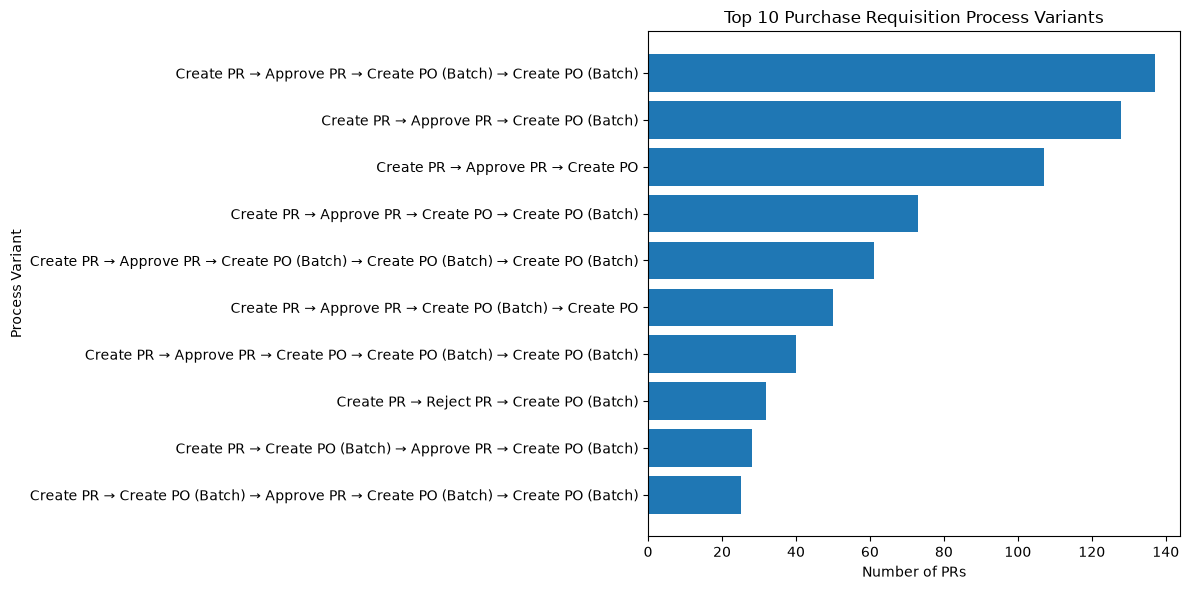

In [55]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.barh(
    top_variants["process_variant"].astype(str)[::-1],
    top_variants["case_count"][::-1]
)

plt.xlabel("Number of PRs")
plt.ylabel("Process Variant")
plt.title("Top 10 Purchase Requisition Process Variants")

plt.tight_layout()
plt.show()

In [56]:
rare_variants = variant_summary[
    variant_summary["case_count"] <= 5
].copy()

print("Number of rare variants:", len(rare_variants))

display(rare_variants.head(20))

Number of rare variants: 58


,process_variant,case_count,percentage
28,Create PR → Create PO (Batch) → Approve PR → C...,5,0.5
29,Create PR → Create PO (Batch) → Reject PR,5,0.5
30,Create PR → Create PO (Batch) → Create PO (Bat...,5,0.5
31,Create PR → Create PO (Batch) → Approve PR → C...,4,0.4
32,Create PO (Batch) → Create PR → Approve PR → C...,4,0.4
33,Create PR → Create PO (Batch) → Approve PR → C...,4,0.4
34,Create PR → Create PO (Batch) → Create PO (Bat...,3,0.3
35,Create PR → Create PO (Batch) → Create PO (Bat...,3,0.3
36,Create PR → Approve PR → Create PO (Batch) → C...,3,0.3
37,Create PR → Approve PR → Create PO (Batch) → C...,3,0.3


In [57]:
for n in [1, 3, 5, 10]:
    coverage = (
        variant_summary.head(n)["case_count"].sum()
        / len(pr_sequences)
        * 100
    )
    
    print(f"Top {n} variants cover {coverage:.2f}% of all PRs")

Top 1 variants cover 13.70% of all PRs
Top 3 variants cover 37.20% of all PRs
Top 5 variants cover 50.60% of all PRs
Top 10 variants cover 68.10% of all PRs


In [58]:
variant_summary.to_csv(
    PROJECT_ROOT / "data" / "process_variants.csv",
    index=False
)

print("Saved:", PROJECT_ROOT / "data" / "process_variants.csv")

Saved: /Users/debarghamishra/Downloads/Agentic_process_Intelligence/data/process_variants.csv


In [59]:
# Calculate transition-level cycle times

transition_stats = calculate_transition_statistics(
    pr_relations
)

display(transition_stats.head(20))

,previous_activity,ocel:activity,occurrences,average_hours,median_hours,p90_hours,max_hours
11,Reject PR,Create PO (Batch),67,0.557235,0.499444,1.150000,1.816667
2,Create PO,Create PO (Batch),195,0.478343,0.399444,1.016833,2.033333
8,Create PR,Approve PR,732,0.468670,0.433333,0.883333,1.000000
0,Approve PR,Create PO,302,0.461810,0.433333,0.865000,1.000000
9,Create PR,Create PO (Batch),188,0.421475,0.416111,0.755472,0.949722
1,Approve PR,Create PO (Batch),598,0.402063,0.350000,0.850000,1.000000
10,Create PR,Reject PR,80,0.401667,0.341667,0.835000,1.000000
5,Create PO (Batch),Create PO (Batch),682,0.350751,0.266944,0.767194,1.633889
4,Create PO (Batch),Create PO,141,0.293002,0.233611,0.633056,0.983333
7,Create PO (Batch),Reject PR,20,0.288417,0.192083,0.755306,0.833056


In [60]:
transition_stats = calculate_transition_statistics(
    pr_relations
)

display(transition_stats)

,previous_activity,ocel:activity,occurrences,average_hours,median_hours,p90_hours,max_hours
11,Reject PR,Create PO (Batch),67,0.557235,0.499444,1.150000,1.816667
2,Create PO,Create PO (Batch),195,0.478343,0.399444,1.016833,2.033333
8,Create PR,Approve PR,732,0.468670,0.433333,0.883333,1.000000
0,Approve PR,Create PO,302,0.461810,0.433333,0.865000,1.000000
9,Create PR,Create PO (Batch),188,0.421475,0.416111,0.755472,0.949722
1,Approve PR,Create PO (Batch),598,0.402063,0.350000,0.850000,1.000000
10,Create PR,Reject PR,80,0.401667,0.341667,0.835000,1.000000
5,Create PO (Batch),Create PO (Batch),682,0.350751,0.266944,0.767194,1.633889
4,Create PO (Batch),Create PO,141,0.293002,0.233611,0.633056,0.983333
7,Create PO (Batch),Reject PR,20,0.288417,0.192083,0.755306,0.833056


In [62]:
transition_bottlenecks = (
    transition_stats
    .sort_values("average_hours", ascending=False)
    .reset_index(drop=True)
)

display(transition_bottlenecks.head(15))

,previous_activity,ocel:activity,occurrences,average_hours,median_hours,p90_hours,max_hours
0,Reject PR,Create PO (Batch),67,0.557235,0.499444,1.150000,1.816667
1,Create PO,Create PO (Batch),195,0.478343,0.399444,1.016833,2.033333
2,Create PR,Approve PR,732,0.468670,0.433333,0.883333,1.000000
3,Approve PR,Create PO,302,0.461810,0.433333,0.865000,1.000000
4,Create PR,Create PO (Batch),188,0.421475,0.416111,0.755472,0.949722
5,Approve PR,Create PO (Batch),598,0.402063,0.350000,0.850000,1.000000
6,Create PR,Reject PR,80,0.401667,0.341667,0.835000,1.000000
7,Create PO (Batch),Create PO (Batch),682,0.350751,0.266944,0.767194,1.633889
8,Create PO (Batch),Create PO,141,0.293002,0.233611,0.633056,0.983333
9,Create PO (Batch),Reject PR,20,0.288417,0.192083,0.755306,0.833056


In [63]:
slowest_transitions = transition_bottlenecks.head(10).copy()

slowest_transitions["transition"] = (
    slowest_transitions["previous_activity"]
    + " → "
    + slowest_transitions["ocel:activity"]
)

display(
    slowest_transitions[
        [
            "transition",
            "occurrences",
            "average_hours",
            "median_hours",
            "p90_hours",
            "max_hours"
        ]
    ]
)

,transition,occurrences,average_hours,median_hours,p90_hours,max_hours
0,Reject PR → Create PO (Batch),67,0.557235,0.499444,1.150000,1.816667
1,Create PO → Create PO (Batch),195,0.478343,0.399444,1.016833,2.033333
2,Create PR → Approve PR,732,0.468670,0.433333,0.883333,1.000000
3,Approve PR → Create PO,302,0.461810,0.433333,0.865000,1.000000
4,Create PR → Create PO (Batch),188,0.421475,0.416111,0.755472,0.949722
5,Approve PR → Create PO (Batch),598,0.402063,0.350000,0.850000,1.000000
6,Create PR → Reject PR,80,0.401667,0.341667,0.835000,1.000000
7,Create PO (Batch) → Create PO (Batch),682,0.350751,0.266944,0.767194,1.633889
8,Create PO (Batch) → Create PO,141,0.293002,0.233611,0.633056,0.983333
9,Create PO (Batch) → Reject PR,20,0.288417,0.192083,0.755306,0.833056


In [66]:
print(pr_relations.columns.tolist())

['ocel:eid', 'ocel:oid', 'ocel:qualifier', 'ocel:activity', 'ocel:timestamp', 'ocel:type', 'ocel:activity_event', 'ocel:timestamp_event']


In [67]:
display(pr_relations.head(1))

,ocel:eid,ocel:oid,ocel:qualifier,ocel:activity,ocel:timestamp,ocel:type,ocel:activity_event,ocel:timestamp_event
111,E1,PR1,None,Create PR,2024-09-02 08:10:53+00:00,Purchase Requisition,Create PR,2024-09-02 08:10:53+00:00


In [68]:
# Rebuild PR relations with event context

pr_relations = relations[
    relations["ocel:type"] == "Purchase Requisition"
].copy()

# Add user, cost center, activity and timestamp from events
pr_relations = pr_relations.merge(
    events[
        [
            "ocel:eid",
            "user",
            "cost_center",
            "ocel:activity",
            "ocel:timestamp"
        ]
    ],
    on="ocel:eid",
    how="left",
    suffixes=("", "_event")
)

# Use the event-level activity/timestamp
pr_relations = pr_relations.rename(
    columns={
        "ocel:activity_event": "activity",
        "ocel:timestamp_event": "timestamp"
    }
)

# Sort chronologically
pr_relations = pr_relations.sort_values(
    ["ocel:oid", "timestamp"]
)

print("Columns:")
print(pr_relations.columns.tolist())

print("\nShape:", pr_relations.shape)

display(
    pr_relations[
        [
            "ocel:oid",
            "ocel:eid",
            "activity",
            "timestamp",
            "user",
            "cost_center"
        ]
    ].head(10)
)

Columns:
['ocel:eid', 'ocel:oid', 'ocel:qualifier', 'ocel:activity', 'ocel:timestamp', 'ocel:type', 'user', 'cost_center', 'activity', 'timestamp']

Shape: (4227, 10)


,ocel:oid,ocel:eid,activity,timestamp,user,cost_center
111,PR1,E1,Create PR,2024-09-02 08:10:53+00:00,User34,CC2
1290,PR1,E2,Approve PR,2024-09-02 08:53:53+00:00,Manager3,CC5
2100,PR1,E3,Create PO (Batch),2024-09-02 09:12:53+00:00,User31,CC12
3848,PR1,E6629,Create PO (Batch),2024-09-02 10:03:56+00:00,User24,CC15
874,PR10,E82,Create PR,2024-09-02 08:41:53+00:00,User45,CC13
2357,PR10,E83,Approve PR,2024-09-02 09:19:53+00:00,Manager10,CC2
3337,PR10,E84,Create PO,2024-09-02 09:44:53+00:00,User30,CC12
54,PR100,E850,Create PR,2024-09-02 08:07:53+00:00,User16,CC17
1190,PR100,E851,Approve PR,2024-09-02 08:50:53+00:00,Manager7,CC9
2795,PR100,E852,Create PO (Batch),2024-09-02 09:30:53+00:00,User24,CC15


In [69]:
# Calculate PR cycle time from the clean PR event data
pr_cycle = calculate_pr_cycle_time(pr_relations)

# Extract one user and cost center per PR
pr_context = (
    pr_relations
    .sort_values("timestamp")
    .groupby("ocel:oid")
    .agg(
        user=("user", "first"),
        cost_center=("cost_center", "first")
    )
    .reset_index()
)

# Merge
pr_analysis = pr_cycle.merge(
    pr_context,
    on="ocel:oid",
    how="left"
)

print("PR analysis shape:", pr_analysis.shape)

display(pr_analysis.head(10))

PR analysis shape: (1000, 6)


,ocel:oid,start_time,end_time,cycle_time_hours,user,cost_center
0,PR1,2024-09-02 08:10:53+00:00,2024-09-02 10:03:56+00:00,1.884167,User34,CC2
1,PR10,2024-09-02 08:41:53+00:00,2024-09-02 09:44:53+00:00,1.050000,User45,CC13
2,PR100,2024-09-02 08:07:53+00:00,2024-09-02 09:30:53+00:00,1.383333,User16,CC17
3,PR1000,2024-09-02 08:10:57+00:00,2024-09-02 09:39:57+00:00,1.483333,User11,CC8
4,PR101,2024-09-02 08:27:53+00:00,2024-09-02 10:06:53+00:00,1.650000,User33,CC19
5,PR102,2024-09-02 08:54:53+00:00,2024-09-02 10:23:53+00:00,1.483333,User26,CC14
6,PR103,2024-09-02 08:29:53+00:00,2024-09-02 09:40:53+00:00,1.183333,User45,CC12
7,PR104,2024-09-02 09:03:53+00:00,2024-09-02 10:18:53+00:00,1.250000,User31,CC12
8,PR105,2024-09-02 08:46:53+00:00,2024-09-02 10:22:56+00:00,1.600833,User40,CC10
9,PR106,2024-09-02 08:50:53+00:00,2024-09-02 10:24:53+00:00,1.566667,User32,CC10


In [70]:
cost_center_analysis = (
    pr_analysis
    .groupby("cost_center")["cycle_time_hours"]
    .agg(
        pr_count="count",
        average_cycle_time="mean",
        median_cycle_time="median",
        p90_cycle_time=lambda x: x.quantile(0.90)
    )
    .reset_index()
    .sort_values("average_cycle_time", ascending=False)
)

display(cost_center_analysis)

,cost_center,pr_count,average_cycle_time,median_cycle_time,p90_cycle_time
7,CC16,50,1.407322,1.408333,1.840639
13,CC3,61,1.385660,1.383333,1.984167
6,CC15,62,1.365838,1.434028,1.848278
9,CC18,65,1.364850,1.383056,1.810000
18,CC8,32,1.336441,1.416667,1.818306
11,CC2,64,1.321372,1.358333,1.873972
4,CC13,51,1.318529,1.349167,1.933611
10,CC19,54,1.317320,1.241528,1.971250
0,CC1,48,1.303432,1.325000,1.900083
2,CC11,45,1.300037,1.266389,1.903722


In [71]:
user_analysis = (
    pr_analysis
    .groupby("user")["cycle_time_hours"]
    .agg(
        pr_count="count",
        average_cycle_time="mean",
        median_cycle_time="median",
        p90_cycle_time=lambda x: x.quantile(0.90)
    )
    .reset_index()
    .sort_values("average_cycle_time", ascending=False)
)

display(user_analysis.head(20))

,user,pr_count,average_cycle_time,median_cycle_time,p90_cycle_time
22,User3,19,1.499240,1.400833,2.077167
3,User12,20,1.487514,1.441667,1.861583
12,User20,24,1.457593,1.424861,1.911167
15,User23,19,1.444678,1.349167,2.350056
41,User47,17,1.431405,1.415833,2.014167
14,User22,24,1.426435,1.441806,2.028222
38,User44,11,1.425732,1.366667,1.850833
27,User34,18,1.397346,1.333611,1.848389
48,User8,15,1.386704,1.416667,1.787000
46,User6,23,1.385495,1.316667,1.949889


In [72]:
p90_threshold = pr_analysis["cycle_time_hours"].quantile(0.90)

slow_prs = pr_analysis[
    pr_analysis["cycle_time_hours"] >= p90_threshold
].copy()

print(f"P90 threshold: {p90_threshold:.2f} hours")
print(f"Number of slow PRs: {len(slow_prs)}")

display(
    slow_prs
    .sort_values("cycle_time_hours", ascending=False)
    .head(20)
)

P90 threshold: 1.87 hours
Number of slow PRs: 100


,ocel:oid,start_time,end_time,cycle_time_hours,user,cost_center
193,PR272,2024-09-02 08:04:54+00:00,2024-09-02 11:03:55+00:00,2.983611,User31,CC9
907,PR915,2024-09-02 08:07:57+00:00,2024-09-02 10:56:57+00:00,2.816667,User20,CC12
386,PR446,2024-09-02 08:08:55+00:00,2024-09-02 10:56:57+00:00,2.800556,User11,CC9
609,PR647,2024-09-02 08:05:56+00:00,2024-09-02 10:49:54+00:00,2.732778,User29,CC3
789,PR809,2024-09-02 08:24:56+00:00,2024-09-02 11:03:55+00:00,2.649722,User10,CC8
287,PR357,2024-09-02 08:09:54+00:00,2024-09-02 10:45:56+00:00,2.600556,User26,CC11
486,PR536,2024-09-02 08:09:55+00:00,2024-09-02 10:45:56+00:00,2.600278,User42,CC6
375,PR436,2024-09-02 08:21:55+00:00,2024-09-02 10:56:57+00:00,2.583889,User45,CC3
239,PR313,2024-09-02 08:06:54+00:00,2024-09-02 10:41:55+00:00,2.583611,User46,CC16
67,PR159,2024-09-02 08:08:53+00:00,2024-09-02 10:42:54+00:00,2.566944,User23,CC7


In [73]:
# Detect rejected Purchase Requisitions

rejected_prs = (
    pr_relations[
        pr_relations["activity"] == "Reject PR"
    ]
    [["ocel:oid", "user", "cost_center", "timestamp"]]
    .drop_duplicates()
)

print("Rejected PRs:", len(rejected_prs))

display(rejected_prs.head(20))

Rejected PRs: 100


,ocel:oid,user,cost_center,timestamp
646,PR108,Manager5,CC17,2024-09-02 08:34:53+00:00
580,PR109,Manager5,CC17,2024-09-02 08:32:53+00:00
2303,PR112,Manager10,CC12,2024-09-02 09:18:53+00:00
1192,PR122,Manager10,CC9,2024-09-02 08:50:53+00:00
2177,PR132,Manager9,CC5,2024-09-02 09:14:53+00:00
1920,PR137,Manager5,CC17,2024-09-02 09:08:53+00:00
2136,PR16,Manager3,CC5,2024-09-02 09:13:53+00:00
1296,PR173,Manager7,CC17,2024-09-02 08:53:54+00:00
2558,PR193,Manager10,CC8,2024-09-02 09:23:54+00:00
2016,PR200,Manager6,CC17,2024-09-02 09:10:54+00:00


In [74]:
# Count PO creation events for each PR

po_creation_counts = (
    pr_relations[
        pr_relations["activity"].isin(
            ["Create PO", "Create PO (Batch)"]
        )
    ]
    .groupby("ocel:oid")
    .size()
    .reset_index(name="po_creation_events")
)

repeated_po_prs = po_creation_counts[
    po_creation_counts["po_creation_events"] > 1
].copy()

print("PRs with repeated PO creation:", len(repeated_po_prs))

display(
    repeated_po_prs
    .sort_values("po_creation_events", ascending=False)
    .head(20)
)

PRs with repeated PO creation: 702


,ocel:oid,po_creation_events
875,PR904,6
673,PR717,6
223,PR306,6
538,PR593,6
738,PR778,6
474,PR535,6
774,PR81,6
139,PR225,6
513,PR570,6
953,PR977,6


In [75]:
# Detect three-way-match mismatches

mismatch_events = events[
    events["ocel:activity"] == "Threeway Match Mismatch Found"
].copy()

print("Mismatch events:", len(mismatch_events))

display(
    mismatch_events[
        [
            "ocel:eid",
            "ocel:activity",
            "ocel:timestamp"
        ]
    ].head(20)
)

Mismatch events: 0


,ocel:eid,ocel:activity,ocel:timestamp


In [76]:
exception_summary = pd.DataFrame({
    "exception_type": [
        "Rejected PR",
        "Repeated PO Creation",
        "Three-way Match Mismatch"
    ],
    "count": [
        len(rejected_prs),
        len(repeated_po_prs),
        len(mismatch_events)
    ]
})

display(exception_summary)

,exception_type,count
0,Rejected PR,100
1,Repeated PO Creation,702
2,Three-way Match Mismatch,0


In [78]:
# Find all three-way-match mismatch events
mismatch_event_ids = events.loc[
    events["ocel:activity"] == "Threeway Match Mismatch Found",
    "ocel:eid"
]

# Get objects connected to those events
mismatch_relations = relations[
    relations["ocel:eid"].isin(mismatch_event_ids)
].copy()

# Add event information using unique column names
event_context = events[
    [
        "ocel:eid",
        "ocel:activity",
        "ocel:timestamp"
    ]
].rename(
    columns={
        "ocel:activity": "event_activity",
        "ocel:timestamp": "event_timestamp"
    }
)

mismatch_relations = mismatch_relations.merge(
    event_context,
    on="ocel:eid",
    how="left"
)

print("Mismatch event-object relationships:", len(mismatch_relations))

display(
    mismatch_relations[
        [
            "ocel:eid",
            "ocel:oid",
            "ocel:type",
            "event_activity",
            "event_timestamp"
        ]
    ].head(30)
)

Mismatch event-object relationships: 0


,ocel:eid,ocel:oid,ocel:type,event_activity,event_timestamp


In [79]:
# Inspect the actual mismatch events in the events dataframe

mismatch_events_check = events[
    events["ocel:activity"].astype(str).str.contains(
        "Mismatch",
        case=False,
        na=False
    )
].copy()

print("Mismatch-related events found:", len(mismatch_events_check))

display(
    mismatch_events_check[
        [
            "ocel:eid",
            "ocel:activity",
            "ocel:timestamp"
        ]
    ].head(20)
)

print("\nEvent ID dtype:", events["ocel:eid"].dtype)
print("Relations Event ID dtype:", relations["ocel:eid"].dtype)

Mismatch-related events found: 77


,ocel:eid,ocel:activity,ocel:timestamp
0,E7244,Three-way Match - Mismatch Found,2024-09-04 09:53:57+00:00
1,E7708,Three-way Match - Mismatch Found,2024-09-04 10:11:57+00:00
2,E4154,Three-way Match - Mismatch Found,2024-09-04 10:40:55+00:00
3,E1989,Three-way Match - Mismatch Found,2024-09-04 10:51:54+00:00
4,E89,Three-way Match - Mismatch Found,2024-09-04 10:58:53+00:00
5,E7190,Three-way Match - Mismatch Found,2024-09-04 11:03:57+00:00
6,E601,Three-way Match - Mismatch Found,2024-09-04 11:21:53+00:00
7,E1967,Three-way Match - Mismatch Found,2024-09-04 11:31:54+00:00
8,E374,Three-way Match - Mismatch Found,2024-09-04 11:45:53+00:00
9,E781,Three-way Match - Mismatch Found,2024-09-04 11:55:53+00:00



Event ID dtype: str
Relations Event ID dtype: str


In [80]:
print("Mismatch event columns:")
print(mismatch_events_check.columns.tolist())

display(mismatch_events_check.head(10))

Mismatch event columns:
['user', 'cost_center', 'ocel:eid', 'ocel:activity', 'ocel:timestamp', 'location']


,user,cost_center,ocel:eid,ocel:activity,ocel:timestamp,location
0,AP5,NaN,E7244,Three-way Match - Mismatch Found,2024-09-04 09:53:57+00:00,NaN
1,AP2,NaN,E7708,Three-way Match - Mismatch Found,2024-09-04 10:11:57+00:00,NaN
2,AP9,NaN,E4154,Three-way Match - Mismatch Found,2024-09-04 10:40:55+00:00,NaN
3,AP6,NaN,E1989,Three-way Match - Mismatch Found,2024-09-04 10:51:54+00:00,NaN
4,AP1,NaN,E89,Three-way Match - Mismatch Found,2024-09-04 10:58:53+00:00,NaN
5,AP7,NaN,E7190,Three-way Match - Mismatch Found,2024-09-04 11:03:57+00:00,NaN
6,AP7,NaN,E601,Three-way Match - Mismatch Found,2024-09-04 11:21:53+00:00,NaN
7,AP9,NaN,E1967,Three-way Match - Mismatch Found,2024-09-04 11:31:54+00:00,NaN
8,AP10,NaN,E374,Three-way Match - Mismatch Found,2024-09-04 11:45:53+00:00,NaN
9,AP7,NaN,E781,Three-way Match - Mismatch Found,2024-09-04 11:55:53+00:00,NaN


In [81]:
# Count all events by cost center and mismatch events by cost center

total_by_cc = (
    events
    .groupby("cost_center")
    .size()
    .reset_index(name="total_events")
)

mismatch_by_cc = (
    mismatch_events_check
    .groupby("cost_center")
    .size()
    .reset_index(name="mismatch_events")
)

mismatch_cc_analysis = total_by_cc.merge(
    mismatch_by_cc,
    on="cost_center",
    how="left"
)

mismatch_cc_analysis["mismatch_events"] = (
    mismatch_cc_analysis["mismatch_events"].fillna(0)
)

mismatch_cc_analysis["mismatch_rate"] = (
    mismatch_cc_analysis["mismatch_events"]
    / mismatch_cc_analysis["total_events"]
    * 100
)

mismatch_cc_analysis = mismatch_cc_analysis.sort_values(
    "mismatch_rate",
    ascending=False
)

display(mismatch_cc_analysis)

,cost_center,total_events,mismatch_events,mismatch_rate
0,CC1,210,0.0,0.0
1,CC10,237,0.0,0.0
18,CC8,224,0.0,0.0
17,CC7,236,0.0,0.0
16,CC6,224,0.0,0.0
15,CC5,240,0.0,0.0
14,CC4,205,0.0,0.0
13,CC3,241,0.0,0.0
12,CC20,225,0.0,0.0
11,CC2,238,0.0,0.0


In [82]:
user_total = (
    events
    .groupby("user")
    .size()
    .reset_index(name="total_events")
)

user_mismatch = (
    mismatch_events_check
    .groupby("user")
    .size()
    .reset_index(name="mismatch_events")
)

mismatch_user_analysis = user_total.merge(
    user_mismatch,
    on="user",
    how="left"
)

mismatch_user_analysis["mismatch_events"] = (
    mismatch_user_analysis["mismatch_events"].fillna(0)
)

mismatch_user_analysis["mismatch_rate"] = (
    mismatch_user_analysis["mismatch_events"]
    / mismatch_user_analysis["total_events"]
    * 100
)

display(
    mismatch_user_analysis
    .sort_values("mismatch_events", ascending=False)
    .head(20)
)

,user,total_events,mismatch_events,mismatch_rate
9,AP9,306,13.0,4.248366
2,AP2,246,11.0,4.471545
6,AP6,263,10.0,3.802281
1,AP10,272,8.0,2.941176
4,AP4,268,8.0,2.985075
7,AP7,273,8.0,2.930403
5,AP5,261,6.0,2.298851
8,AP8,256,5.0,1.953125
0,AP1,284,4.0,1.408451
3,AP3,271,4.0,1.476015


In [83]:
# Create PR-level exception flags

exception_flags = (
    pr_relations
    .groupby("ocel:oid")
    .agg(
        rejected_pr=("activity", lambda x: (x == "Reject PR").any()),
        po_creation_count=(
            "activity",
            lambda x: x.isin(["Create PO", "Create PO (Batch)"]).sum()
        )
    )
    .reset_index()
)

# A PR is considered to have repeated PO creation
exception_flags["repeated_po_creation"] = (
    exception_flags["po_creation_count"] > 1
)

# Merge flags into PR-level analysis
pr_analysis = pr_analysis.drop(
    columns=["rejected_pr", "po_creation_count", "repeated_po_creation"],
    errors="ignore"
)

pr_analysis = pr_analysis.merge(
    exception_flags,
    on="ocel:oid",
    how="left"
)

display(pr_analysis.head(10))

,ocel:oid,start_time,end_time,cycle_time_hours,user,cost_center,rejected_pr,po_creation_count,repeated_po_creation
0,PR1,2024-09-02 08:10:53+00:00,2024-09-02 10:03:56+00:00,1.884167,User34,CC2,False,2,True
1,PR10,2024-09-02 08:41:53+00:00,2024-09-02 09:44:53+00:00,1.050000,User45,CC13,False,1,False
2,PR100,2024-09-02 08:07:53+00:00,2024-09-02 09:30:53+00:00,1.383333,User16,CC17,False,1,False
3,PR1000,2024-09-02 08:10:57+00:00,2024-09-02 09:39:57+00:00,1.483333,User11,CC8,False,2,True
4,PR101,2024-09-02 08:27:53+00:00,2024-09-02 10:06:53+00:00,1.650000,User33,CC19,False,2,True
5,PR102,2024-09-02 08:54:53+00:00,2024-09-02 10:23:53+00:00,1.483333,User26,CC14,False,2,True
6,PR103,2024-09-02 08:29:53+00:00,2024-09-02 09:40:53+00:00,1.183333,User45,CC12,False,3,True
7,PR104,2024-09-02 09:03:53+00:00,2024-09-02 10:18:53+00:00,1.250000,User31,CC12,False,5,True
8,PR105,2024-09-02 08:46:53+00:00,2024-09-02 10:22:56+00:00,1.600833,User40,CC10,False,5,True
9,PR106,2024-09-02 08:50:53+00:00,2024-09-02 10:24:53+00:00,1.566667,User32,CC10,False,1,False


In [84]:
exception_impact = (
    pr_analysis
    .groupby(["rejected_pr", "repeated_po_creation"])["cycle_time_hours"]
    .agg(
        pr_count="count",
        average_cycle_time="mean",
        median_cycle_time="median",
        p90_cycle_time=lambda x: x.quantile(0.90)
    )
    .reset_index()
)

display(exception_impact)

,rejected_pr,repeated_po_creation,pr_count,average_cycle_time,median_cycle_time,p90_cycle_time
0,False,False,235,1.052979,1.066667,1.633333
1,False,True,665,1.428478,1.416389,1.966167
2,True,False,63,0.855608,0.866944,1.613333
3,True,True,37,1.349407,1.315556,1.833778


In [85]:
po_impact = (
    pr_analysis
    .groupby("repeated_po_creation")["cycle_time_hours"]
    .agg(
        pr_count="count",
        average_cycle_time="mean",
        median_cycle_time="median",
        p90_cycle_time=lambda x: x.quantile(0.90)
    )
    .reset_index()
)

display(po_impact)

,repeated_po_creation,pr_count,average_cycle_time,median_cycle_time,p90_cycle_time
0,False,298,1.011253,1.016667,1.633333
1,True,702,1.424310,1.415833,1.965833


In [86]:
normal_avg = pr_analysis.loc[
    ~pr_analysis["repeated_po_creation"],
    "cycle_time_hours"
].mean()

repeated_avg = pr_analysis.loc[
    pr_analysis["repeated_po_creation"],
    "cycle_time_hours"
].mean()

penalty = repeated_avg - normal_avg
penalty_pct = penalty / normal_avg * 100

print(f"Normal PR average cycle time:   {normal_avg:.2f} hours")
print(f"Repeated-PO PR average time:    {repeated_avg:.2f} hours")
print(f"Cycle-time penalty:              {penalty:.2f} hours")
print(f"Relative increase:               {penalty_pct:.2f}%")

Normal PR average cycle time:   1.01 hours
Repeated-PO PR average time:    1.42 hours
Cycle-time penalty:              0.41 hours
Relative increase:               40.85%


In [87]:
# ============================================
# Predictive ML Dataset
# ============================================

# Get PR approval timing
pr_approval = calculate_pr_approval_time(pr_relations)

# Keep only useful columns
pr_approval_features = pr_approval[
    [
        "ocel:oid",
        "approval_time_hours"
    ]
].copy()

# Merge with PR-level cycle-time data
ml_df = pr_analysis[
    [
        "ocel:oid",
        "cycle_time_hours",
        "user",
        "cost_center"
    ]
].merge(
    pr_approval_features,
    on="ocel:oid",
    how="left"
)

# Define slow PR threshold using P90
slow_threshold = ml_df["cycle_time_hours"].quantile(0.90)

ml_df["is_slow_pr"] = (
    ml_df["cycle_time_hours"] >= slow_threshold
).astype(int)

print("Slow PR threshold:", round(slow_threshold, 3), "hours")
print("ML dataset shape:", ml_df.shape)

display(ml_df.head(10))

Slow PR threshold: 1.866 hours
ML dataset shape: (1000, 6)


,ocel:oid,cycle_time_hours,user,cost_center,approval_time_hours,is_slow_pr
0,PR1,1.884167,User34,CC2,0.716667,1
1,PR10,1.050000,User45,CC13,0.633333,0
2,PR100,1.383333,User16,CC17,0.716667,0
3,PR1000,1.483333,User11,CC8,0.683333,0
4,PR101,1.650000,User33,CC19,0.800000,0
5,PR102,1.483333,User26,CC14,0.683333,0
6,PR103,1.183333,User45,CC12,0.383333,0
7,PR104,1.250000,User31,CC12,0.833333,0
8,PR105,1.600833,User40,CC10,0.566667,0
9,PR106,1.566667,User32,CC10,0.600000,0


In [88]:
print("Target distribution:")
print(ml_df["is_slow_pr"].value_counts())

print("\nTarget percentage:")
print(
    ml_df["is_slow_pr"]
    .value_counts(normalize=True)
    .mul(100)
)

Target distribution:
is_slow_pr
0    900
1    100
Name: count, dtype: int64

Target percentage:
is_slow_pr
0    90.0
1    10.0
Name: proportion, dtype: float64


In [90]:
%pip install scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 46.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [scikit-learn] [scikit-learn]
Note: you may need to restart the kernel to use updated packages.


In [91]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Features available for prediction
X = ml_df[
    [
        "approval_time_hours",
        "user",
        "cost_center"
    ]
].copy()

y = ml_df["is_slow_pr"].copy()

# Separate feature types
numeric_features = [
    "approval_time_hours"
]

categorical_features = [
    "user",
    "cost_center"
]

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            SimpleImputer(strategy="median"),
            numeric_features
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                (
                    "onehot",
                    OneHotEncoder(
                        handle_unknown="ignore"
                    )
                )
            ]),
            categorical_features
        )
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Slow PRs in train:", y_train.sum())
print("Slow PRs in test:", y_test.sum())

Training samples: 800
Testing samples: 200
Slow PRs in train: 80
Slow PRs in test: 20


In [92]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                max_depth=10,
                min_samples_split=10,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [93]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1 Score :", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy : 0.675
Precision: 0.0909
Recall   : 0.25
F1 Score : 0.1333
ROC-AUC  : 0.4969

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.72      0.80       180
           1       0.09      0.25      0.13        20

    accuracy                           0.68       200
   macro avg       0.49      0.49      0.47       200
weighted avg       0.82      0.68      0.73       200



In [94]:
# ============================================
# Leakage-free early-stage prediction features
# ============================================

# Get the Create PR event for every PR
create_pr_features = (
    pr_relations[
        pr_relations["activity"] == "Create PR"
    ][
        [
            "ocel:oid",
            "timestamp",
            "user",
            "cost_center"
        ]
    ]
    .drop_duplicates("ocel:oid")
    .copy()
)

# Time-based features available at PR creation
create_pr_features["creation_hour"] = (
    create_pr_features["timestamp"].dt.hour
)

create_pr_features["creation_dayofweek"] = (
    create_pr_features["timestamp"].dt.dayofweek
)

create_pr_features["creation_day"] = (
    create_pr_features["timestamp"].dt.day
)

# Merge with target
early_ml_df = create_pr_features.merge(
    ml_df[
        [
            "ocel:oid",
            "cycle_time_hours",
            "is_slow_pr"
        ]
    ],
    on="ocel:oid",
    how="inner"
)

print("Early-stage ML dataset:", early_ml_df.shape)

display(early_ml_df.head(10))

Early-stage ML dataset: (1000, 9)


,ocel:oid,timestamp,user,cost_center,creation_hour,creation_dayofweek,creation_day,cycle_time_hours,is_slow_pr
0,PR1,2024-09-02 08:10:53+00:00,User34,CC2,8,0,2,1.884167,1
1,PR10,2024-09-02 08:41:53+00:00,User45,CC13,8,0,2,1.050000,0
2,PR100,2024-09-02 08:07:53+00:00,User16,CC17,8,0,2,1.383333,0
3,PR1000,2024-09-02 08:10:57+00:00,User11,CC8,8,0,2,1.483333,0
4,PR101,2024-09-02 08:27:53+00:00,User33,CC19,8,0,2,1.650000,0
5,PR102,2024-09-02 08:54:53+00:00,User26,CC14,8,0,2,1.483333,0
6,PR103,2024-09-02 08:29:53+00:00,User45,CC12,8,0,2,1.183333,0
7,PR104,2024-09-02 09:03:53+00:00,User31,CC12,9,0,2,1.250000,0
8,PR105,2024-09-02 08:46:53+00:00,User40,CC10,8,0,2,1.600833,0
9,PR106,2024-09-02 08:50:53+00:00,User32,CC10,8,0,2,1.566667,0


In [95]:
print(early_ml_df[
    [
        "user",
        "cost_center",
        "creation_hour",
        "creation_dayofweek",
        "creation_day",
        "is_slow_pr"
    ]
].describe(include="all"))

          user cost_center  creation_hour  creation_dayofweek  creation_day  \
count     1000        1000    1000.000000              1000.0        1000.0   
unique      50          20            NaN                 NaN           NaN   
top     User37        CC15            NaN                 NaN           NaN   
freq        31          63            NaN                 NaN           NaN   
mean       NaN         NaN       8.067000                 0.0           2.0   
std        NaN         NaN       0.250147                 0.0           0.0   
min        NaN         NaN       8.000000                 0.0           2.0   
25%        NaN         NaN       8.000000                 0.0           2.0   
50%        NaN         NaN       8.000000                 0.0           2.0   
75%        NaN         NaN       8.000000                 0.0           2.0   
max        NaN         NaN       9.000000                 0.0           2.0   

        is_slow_pr  
count   1000.00000  
unique   

In [96]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Features available at Create PR time
X = early_ml_df[
    [
        "user",
        "cost_center",
        "creation_hour",
        "creation_dayofweek",
        "creation_day"
    ]
].copy()

y = early_ml_df["is_slow_pr"].copy()

numeric_features = [
    "creation_hour",
    "creation_dayofweek",
    "creation_day"
]

categorical_features = [
    "user",
    "cost_center"
]

preprocessor_early = ColumnTransformer(
    transformers=[
        (
            "numeric",
            SimpleImputer(strategy="median"),
            numeric_features
        ),
        (
            "categorical",
            Pipeline([
                (
                    "imputer",
                    SimpleImputer(strategy="most_frequent")
                ),
                (
                    "onehot",
                    OneHotEncoder(handle_unknown="ignore")
                )
            ]),
            categorical_features
        )
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

early_rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor_early),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=500,
                max_depth=12,
                min_samples_split=8,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

early_rf_model.fit(X_train, y_train)

print("Early-stage Random Forest trained.")

Early-stage Random Forest trained.


In [97]:
y_pred = early_rf_model.predict(X_test)
y_prob = early_rf_model.predict_proba(X_test)[:, 1]

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1 Score :", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy : 0.62
Precision: 0.1
Recall   : 0.35
F1 Score : 0.1556
ROC-AUC  : 0.4519

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.65      0.75       180
           1       0.10      0.35      0.16        20

    accuracy                           0.62       200
   macro avg       0.50      0.50      0.46       200
weighted avg       0.82      0.62      0.69       200



In [98]:
print("Previous model ROC-AUC : 0.4969")
print(
    "Early-stage model ROC-AUC:",
    round(roc_auc_score(y_test, y_prob), 4)
)

Previous model ROC-AUC : 0.4969
Early-stage model ROC-AUC: 0.4519


In [99]:
# ============================================
# Early-stage operational features
# ============================================

create_pr = (
    pr_relations[
        pr_relations["activity"] == "Create PR"
    ][
        [
            "ocel:oid",
            "timestamp",
            "user",
            "cost_center"
        ]
    ]
    .drop_duplicates("ocel:oid")
    .copy()
)

# Make sure timestamps are datetime
create_pr["timestamp"] = pd.to_datetime(
    create_pr["timestamp"]
)

# Sort chronologically
create_pr = create_pr.sort_values(
    ["timestamp", "ocel:oid"]
).reset_index(drop=True)

# ------------------------------------------------
# 1. Previous PR count for the same user
# ------------------------------------------------
create_pr["user_prior_pr_count"] = (
    create_pr
    .groupby("user")
    .cumcount()
)

# ------------------------------------------------
# 2. Previous PR count for the same cost center
# ------------------------------------------------
create_pr["cost_center_prior_pr_count"] = (
    create_pr
    .groupby("cost_center")
    .cumcount()
)

# ------------------------------------------------
# 3. Time since previous PR by same user
# ------------------------------------------------
create_pr["user_previous_timestamp"] = (
    create_pr
    .groupby("user")["timestamp"]
    .shift(1)
)

create_pr["user_time_since_previous_pr_hours"] = (
    (
        create_pr["timestamp"]
        - create_pr["user_previous_timestamp"]
    ).dt.total_seconds() / 3600
)

# ------------------------------------------------
# 4. Time since previous PR in same cost center
# ------------------------------------------------
create_pr["cc_previous_timestamp"] = (
    create_pr
    .groupby("cost_center")["timestamp"]
    .shift(1)
)

create_pr["cc_time_since_previous_pr_hours"] = (
    (
        create_pr["timestamp"]
        - create_pr["cc_previous_timestamp"]
    ).dt.total_seconds() / 3600
)

# ------------------------------------------------
# 5. Calendar features
# ------------------------------------------------
create_pr["creation_hour"] = (
    create_pr["timestamp"].dt.hour
)

create_pr["creation_minute"] = (
    create_pr["timestamp"].dt.minute
)

create_pr["creation_dayofweek"] = (
    create_pr["timestamp"].dt.dayofweek
)

# ------------------------------------------------
# Combine with target
# ------------------------------------------------
early_ml_df = create_pr.merge(
    ml_df[
        [
            "ocel:oid",
            "cycle_time_hours",
            "is_slow_pr"
        ]
    ],
    on="ocel:oid",
    how="inner"
)

print("Dataset shape:", early_ml_df.shape)

display(
    early_ml_df[
        [
            "ocel:oid",
            "user",
            "cost_center",
            "user_prior_pr_count",
            "cost_center_prior_pr_count",
            "user_time_since_previous_pr_hours",
            "cc_time_since_previous_pr_hours",
            "creation_hour",
            "creation_minute",
            "creation_dayofweek",
            "is_slow_pr"
        ]
    ].head(15)
)

Dataset shape: (1000, 15)


,ocel:oid,user,cost_center,user_prior_pr_count,cost_center_prior_pr_count,user_time_since_previous_pr_hours,cc_time_since_previous_pr_hours,creation_hour,creation_minute,creation_dayofweek,is_slow_pr
0,PR31,User17,CC11,0,0,NaN,NaN,8,4,0,0
1,PR63,User42,CC15,0,0,NaN,NaN,8,4,0,1
2,PR272,User31,CC9,0,0,NaN,NaN,8,4,0,1
3,PR276,User43,CC16,0,0,NaN,NaN,8,4,0,0
4,PR304,User17,CC6,1,0,0.000278,NaN,8,4,0,0
5,PR316,User34,CC20,0,0,NaN,NaN,8,4,0,1
6,PR338,User18,CC19,0,0,NaN,NaN,8,4,0,0
7,PR496,User35,CC18,0,0,NaN,NaN,8,4,0,0
8,PR509,User16,CC3,0,0,NaN,NaN,8,4,0,1
9,PR762,User19,CC3,0,1,NaN,0.000278,8,4,0,0


In [100]:
feature_check = early_ml_df[
    [
        "user_prior_pr_count",
        "cost_center_prior_pr_count",
        "user_time_since_previous_pr_hours",
        "cc_time_since_previous_pr_hours",
        "creation_hour",
        "creation_minute",
        "creation_dayofweek",
        "is_slow_pr"
    ]
].corr(numeric_only=True)

display(feature_check["is_slow_pr"].sort_values(ascending=False))

is_slow_pr                           1.000000
user_time_since_previous_pr_hours   -0.045222
cc_time_since_previous_pr_hours     -0.047738
creation_hour                       -0.049329
creation_minute                     -0.205550
user_prior_pr_count                 -0.219006
cost_center_prior_pr_count          -0.236239
creation_dayofweek                        NaN
Name: is_slow_pr, dtype: float64

In [101]:
from sklearn.ensemble import RandomForestClassifier

# Features available at PR creation time
feature_columns = [
    "user",
    "cost_center",
    "user_prior_pr_count",
    "cost_center_prior_pr_count",
    "user_time_since_previous_pr_hours",
    "cc_time_since_previous_pr_hours",
    "creation_hour",
    "creation_minute",
    "creation_dayofweek"
]

X = early_ml_df[feature_columns].copy()
y = early_ml_df["is_slow_pr"].copy()

numeric_features = [
    "user_prior_pr_count",
    "cost_center_prior_pr_count",
    "user_time_since_previous_pr_hours",
    "cc_time_since_previous_pr_hours",
    "creation_hour",
    "creation_minute",
    "creation_dayofweek"
]

categorical_features = [
    "user",
    "cost_center"
]

preprocessor_operational = ColumnTransformer(
    transformers=[
        (
            "numeric",
            SimpleImputer(strategy="median"),
            numeric_features
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_features
        )
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

operational_rf = Pipeline(
    steps=[
        ("preprocessor", preprocessor_operational),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=500,
                max_depth=12,
                min_samples_split=8,
                min_samples_leaf=3,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

operational_rf.fit(X_train, y_train)

print("Operational Random Forest trained successfully.")

Operational Random Forest trained successfully.


In [102]:
y_pred = operational_rf.predict(X_test)
y_prob = operational_rf.predict_proba(X_test)[:, 1]

operational_auc = roc_auc_score(y_test, y_prob)

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1 Score :", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC  :", round(operational_auc, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

Accuracy : 0.725
Precision: 0.1818
Recall   : 0.5
F1 Score : 0.2667
ROC-AUC  : 0.7164

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.75      0.83       180
           1       0.18      0.50      0.27        20

    accuracy                           0.72       200
   macro avg       0.56      0.62      0.55       200
weighted avg       0.86      0.72      0.77       200



In [103]:
print("Model comparison")
print("=" * 45)

print(f"Original model ROC-AUC       : 0.4969")
print(f"Early-stage model ROC-AUC    : 0.4519")
print(f"Operational model ROC-AUC    : {operational_auc:.4f}")

Model comparison
Original model ROC-AUC       : 0.4969
Early-stage model ROC-AUC    : 0.4519
Operational model ROC-AUC    : 0.7164


In [104]:
# ============================================
# Feature Importance
# ============================================

# Get transformed feature names
feature_names = (
    operational_rf
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Get Random Forest importance
importances = (
    operational_rf
    .named_steps["classifier"]
    .feature_importances_
)

feature_importance = (
    pd.DataFrame({
        "feature": feature_names,
        "importance": importances
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

display(feature_importance.head(20))

,feature,importance
0,numeric__creation_minute,0.176118
1,numeric__user_prior_pr_count,0.174353
2,numeric__cost_center_prior_pr_count,0.168959
3,numeric__cc_time_since_previous_pr_hours,0.083271
4,numeric__user_time_since_previous_pr_hours,0.076659
5,categorical__cost_center_CC4,0.018036
6,categorical__user_User20,0.017720
7,categorical__user_User1,0.014713
8,categorical__user_User27,0.012752
9,categorical__cost_center_CC11,0.011906


In [105]:
feature_importance["feature"] = (
    feature_importance["feature"]
    .str.replace(
        "numeric__",
        "",
        regex=False
    )
    .str.replace(
        "categorical__",
        "",
        regex=False
    )
)

display(feature_importance.head(20))

,feature,importance
0,creation_minute,0.176118
1,user_prior_pr_count,0.174353
2,cost_center_prior_pr_count,0.168959
3,cc_time_since_previous_pr_hours,0.083271
4,user_time_since_previous_pr_hours,0.076659
5,cost_center_CC4,0.018036
6,user_User20,0.017720
7,user_User1,0.014713
8,user_User27,0.012752
9,cost_center_CC11,0.011906


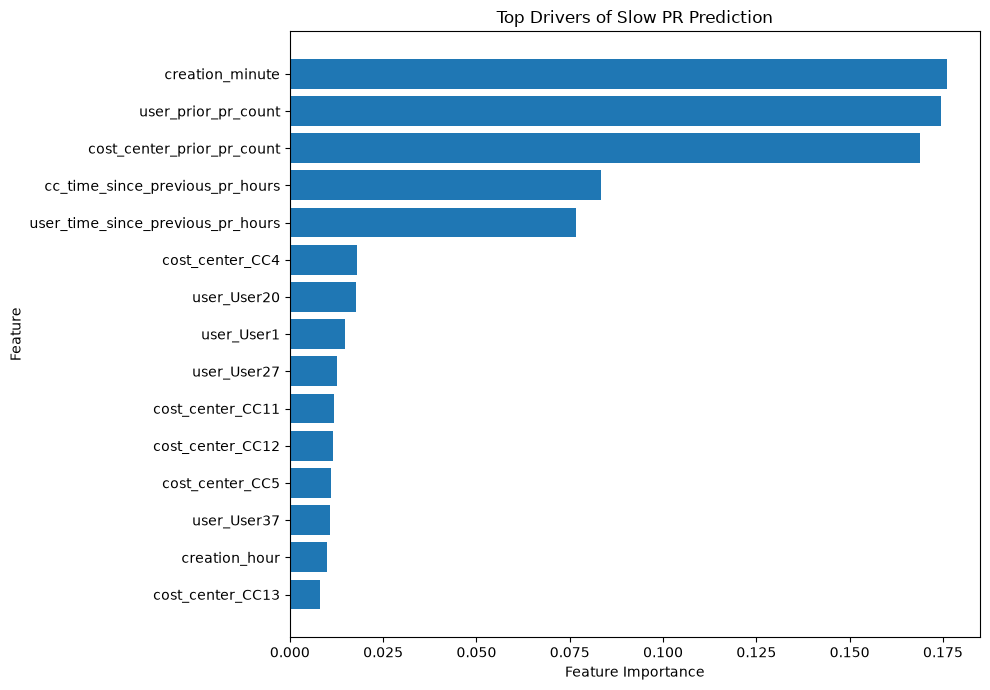

In [106]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(15).sort_values(
    "importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["feature"],
    top_features["importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top Drivers of Slow PR Prediction")

plt.tight_layout()
plt.show()

In [107]:
# ============================================
# Generate Slow-PR Risk Scores
# ============================================

risk_features = early_ml_df[
    feature_columns
].copy()

# Probability of being a slow PR
early_ml_df["slow_pr_probability"] = (
    operational_rf.predict_proba(risk_features)[:, 1]
)

# Convert probability into risk bands
early_ml_df["risk_band"] = pd.cut(
    early_ml_df["slow_pr_probability"],
    bins=[-0.01, 0.30, 0.60, 0.80, 1.01],
    labels=[
        "Low",
        "Medium",
        "High",
        "Critical"
    ]
)

# Sort highest-risk PRs first
risk_scores = early_ml_df.sort_values(
    "slow_pr_probability",
    ascending=False
).copy()

display(
    risk_scores[
        [
            "ocel:oid",
            "user",
            "cost_center",
            "slow_pr_probability",
            "risk_band",
            "cycle_time_hours",
            "is_slow_pr"
        ]
    ].head(20)
)

,ocel:oid,user,cost_center,slow_pr_probability,risk_band,cycle_time_hours,is_slow_pr
49,PR838,User23,CC16,0.881482,Critical,2.482500,1
57,PR258,User3,CC3,0.856352,Critical,2.067222,1
41,PR260,User3,CC2,0.852822,Critical,2.116944,1
28,PR647,User29,CC3,0.850639,Critical,2.732778,1
3,PR276,User43,CC16,0.850313,Critical,1.100000,0
8,PR509,User16,CC3,0.845079,Critical,2.332778,1
42,PR313,User46,CC16,0.844244,Critical,2.583611,1
37,PR15,User20,CC2,0.841893,Critical,1.050000,0
39,PR69,User4,CC11,0.839571,Critical,2.100556,1
72,PR159,User23,CC7,0.837162,Critical,2.566944,1


In [108]:
risk_distribution = (
    risk_scores["risk_band"]
    .value_counts()
    .reindex(
        ["Low", "Medium", "High", "Critical"],
        fill_value=0
    )
    .reset_index()
)

risk_distribution.columns = [
    "risk_band",
    "pr_count"
]

risk_distribution["percentage"] = (
    risk_distribution["pr_count"]
    / len(risk_scores)
    * 100
)

display(risk_distribution)

,risk_band,pr_count,percentage
0,Low,473,47.3
1,Medium,393,39.3
2,High,100,10.0
3,Critical,34,3.4


In [109]:
pr_risk_table = risk_scores[
    [
        "ocel:oid",
        "user",
        "cost_center",
        "slow_pr_probability",
        "risk_band",
        "cycle_time_hours",
        "is_slow_pr"
    ]
].copy()

pr_risk_table.to_csv(
    PROJECT_ROOT / "data" / "pr_risk_scores.csv",
    index=False
)

print(
    "Saved:",
    PROJECT_ROOT / "data" / "pr_risk_scores.csv"
)

Saved: /Users/debarghamishra/Downloads/Agentic_process_Intelligence/data/pr_risk_scores.csv


In [110]:
critical_prs = risk_scores[
    risk_scores["risk_band"].isin(
        ["High", "Critical"]
    )
].head(20)

display(
    critical_prs[
        [
            "ocel:oid",
            "user",
            "cost_center",
            "slow_pr_probability",
            "risk_band"
        ]
    ]
)

,ocel:oid,user,cost_center,slow_pr_probability,risk_band
49,PR838,User23,CC16,0.881482,Critical
57,PR258,User3,CC3,0.856352,Critical
41,PR260,User3,CC2,0.852822,Critical
28,PR647,User29,CC3,0.850639,Critical
3,PR276,User43,CC16,0.850313,Critical
8,PR509,User16,CC3,0.845079,Critical
42,PR313,User46,CC16,0.844244,Critical
37,PR15,User20,CC2,0.841893,Critical
39,PR69,User4,CC11,0.839571,Critical
72,PR159,User23,CC7,0.837162,Critical


In [111]:
# ============================================
# Historical workload benchmarks
# ============================================

user_workload_threshold = early_ml_df[
    "user_prior_pr_count"
].quantile(0.75)

cc_workload_threshold = early_ml_df[
    "cost_center_prior_pr_count"
].quantile(0.75)

user_gap_threshold = early_ml_df[
    "user_time_since_previous_pr_hours"
].quantile(0.25)

cc_gap_threshold = early_ml_df[
    "cc_time_since_previous_pr_hours"
].quantile(0.25)

print("User workload threshold:", user_workload_threshold)
print("Cost-center workload threshold:", cc_workload_threshold)
print("User activity-gap threshold:", user_gap_threshold)
print("Cost-center activity-gap threshold:", cc_gap_threshold)

User workload threshold: 15.0
Cost-center workload threshold: 37.0
User activity-gap threshold: 0.01638888888888889
Cost-center activity-gap threshold: 0.0005555555555555556


In [112]:
# ============================================
# Generate human-readable risk explanations
# ============================================

def explain_pr_risk(row):
    reasons = []

    if row["user_prior_pr_count"] >= user_workload_threshold:
        reasons.append(
            "high prior PR volume for the user"
        )

    if row["cost_center_prior_pr_count"] >= cc_workload_threshold:
        reasons.append(
            "high prior PR volume for the cost center"
        )

    if (
        pd.notna(row["user_time_since_previous_pr_hours"])
        and
        row["user_time_since_previous_pr_hours"] <= user_gap_threshold
    ):
        reasons.append(
            "recent PR activity from the same user"
        )

    if (
        pd.notna(row["cc_time_since_previous_pr_hours"])
        and
        row["cc_time_since_previous_pr_hours"] <= cc_gap_threshold
    ):
        reasons.append(
            "recent PR activity in the same cost center"
        )

    if not reasons:
        reasons.append(
            "no dominant workload signal identified"
        )

    return "; ".join(reasons)


risk_scores["risk_explanation"] = (
    risk_scores.apply(
        explain_pr_risk,
        axis=1
    )
)

display(
    risk_scores[
        [
            "ocel:oid",
            "slow_pr_probability",
            "risk_band",
            "risk_explanation"
        ]
    ].head(20)
)

,ocel:oid,slow_pr_probability,risk_band,risk_explanation
49,PR838,0.881482,Critical,no dominant workload signal identified
57,PR258,0.856352,Critical,no dominant workload signal identified
41,PR260,0.852822,Critical,recent PR activity in the same cost center
28,PR647,0.850639,Critical,recent PR activity from the same user
3,PR276,0.850313,Critical,no dominant workload signal identified
8,PR509,0.845079,Critical,no dominant workload signal identified
42,PR313,0.844244,Critical,recent PR activity from the same user
37,PR15,0.841893,Critical,no dominant workload signal identified
39,PR69,0.839571,Critical,no dominant workload signal identified
72,PR159,0.837162,Critical,no dominant workload signal identified


In [113]:
pr_intelligence = risk_scores[
    [
        "ocel:oid",
        "user",
        "cost_center",
        "slow_pr_probability",
        "risk_band",
        "risk_explanation",
        "cycle_time_hours",
        "is_slow_pr"
    ]
].copy()

display(pr_intelligence.head(20))

,ocel:oid,user,cost_center,slow_pr_probability,risk_band,risk_explanation,cycle_time_hours,is_slow_pr
49,PR838,User23,CC16,0.881482,Critical,no dominant workload signal identified,2.482500,1
57,PR258,User3,CC3,0.856352,Critical,no dominant workload signal identified,2.067222,1
41,PR260,User3,CC2,0.852822,Critical,recent PR activity in the same cost center,2.116944,1
28,PR647,User29,CC3,0.850639,Critical,recent PR activity from the same user,2.732778,1
3,PR276,User43,CC16,0.850313,Critical,no dominant workload signal identified,1.100000,0
8,PR509,User16,CC3,0.845079,Critical,no dominant workload signal identified,2.332778,1
42,PR313,User46,CC16,0.844244,Critical,recent PR activity from the same user,2.583611,1
37,PR15,User20,CC2,0.841893,Critical,no dominant workload signal identified,1.050000,0
39,PR69,User4,CC11,0.839571,Critical,no dominant workload signal identified,2.100556,1
72,PR159,User23,CC7,0.837162,Critical,no dominant workload signal identified,2.566944,1


In [114]:
pr_intelligence.to_csv(
    PROJECT_ROOT / "data" / "pr_intelligence.csv",
    index=False
)

print(
    "Saved:",
    PROJECT_ROOT / "data" / "pr_intelligence.csv"
)

Saved: /Users/debarghamishra/Downloads/Agentic_process_Intelligence/data/pr_intelligence.csv


In [115]:
# ============================================
# Build RAG Knowledge Base
# ============================================

import json
from pathlib import Path

rag_dir = PROJECT_ROOT / "data" / "rag"
rag_dir.mkdir(parents=True, exist_ok=True)

documents = []


def add_document(doc_id, title, content, source):
    documents.append({
        "id": doc_id,
        "title": title,
        "content": content,
        "source": source
    })


# --------------------------------------------
# 1. Overall P2P process summary
# --------------------------------------------

add_document(
    "kpi_001",
    "P2P Process KPI Summary",
    """
Purchase-to-pay process summary:

Total Purchase Requisitions: 1000
Approved Purchase Requisitions: 900
Rejected Purchase Requisitions: 100
Approval Rate: 90.0%
Rejection Rate: 10.0%

Average PR Cycle Time: 1.301 hours
Median PR Cycle Time: 1.300 hours
P90 PR Cycle Time: 1.866 hours

Three-way Match Events: 900
Successful Matches: 823
Mismatch Events: 77
Three-way Match Success Rate: 91.44%
Three-way Match Mismatch Rate: 8.56%
""",
    "process_kpis"
)


# --------------------------------------------
# 2. Process variants
# --------------------------------------------

for idx, row in variant_summary.iterrows():

    add_document(
        f"variant_{idx}",
        f"Process Variant {idx + 1}",
        (
            f"Purchase Requisition process variant:\n"
            f"{row['process_variant']}\n\n"
            f"Number of PRs following this variant: "
            f"{int(row['case_count'])}\n"
            f"Percentage of all PRs: "
            f"{row['percentage']:.2f}%"
        ),
        "process_variants"
    )


# --------------------------------------------
# 3. Transition bottlenecks
# --------------------------------------------

for idx, row in transition_bottlenecks.iterrows():

    add_document(
        f"transition_{idx}",
        (
            f"Transition: "
            f"{row['previous_activity']} → "
            f"{row['ocel:activity']}"
        ),
        (
            f"Process transition analysis:\n"
            f"Previous activity: {row['previous_activity']}\n"
            f"Next activity: {row['ocel:activity']}\n"
            f"Occurrences: {int(row['occurrences'])}\n"
            f"Average duration: {row['average_hours']:.3f} hours\n"
            f"Median duration: {row['median_hours']:.3f} hours\n"
            f"P90 duration: {row['p90_hours']:.3f} hours\n"
            f"Maximum duration: {row['max_hours']:.3f} hours"
        ),
        "transition_analysis"
    )


# --------------------------------------------
# 4. Exception impact
# --------------------------------------------

for idx, row in exception_impact.iterrows():

    add_document(
        f"exception_impact_{idx}",
        "Exception Impact Analysis",
        (
            f"Rejected PR: {bool(row['rejected_pr'])}\n"
            f"Repeated PO creation: "
            f"{bool(row['repeated_po_creation'])}\n"
            f"PR count: {int(row['pr_count'])}\n"
            f"Average cycle time: "
            f"{row['average_cycle_time']:.3f} hours\n"
            f"Median cycle time: "
            f"{row['median_cycle_time']:.3f} hours\n"
            f"P90 cycle time: "
            f"{row['p90_cycle_time']:.3f} hours"
        ),
        "exception_impact"
    )


# --------------------------------------------
# 5. Cost-center analysis
# --------------------------------------------

for idx, row in cost_center_analysis.iterrows():

    add_document(
        f"cost_center_{idx}",
        f"Cost Center {row['cost_center']} Performance",
        (
            f"Cost center: {row['cost_center']}\n"
            f"PR count: {int(row['pr_count'])}\n"
            f"Average cycle time: "
            f"{row['average_cycle_time']:.3f} hours\n"
            f"Median cycle time: "
            f"{row['median_cycle_time']:.3f} hours\n"
            f"P90 cycle time: "
            f"{row['p90_cycle_time']:.3f} hours"
        ),
        "cost_center_analysis"
    )


# --------------------------------------------
# 6. User analysis
# --------------------------------------------

for idx, row in user_analysis.iterrows():

    add_document(
        f"user_{idx}",
        f"User {row['user']} Performance",
        (
            f"User: {row['user']}\n"
            f"PR count: {int(row['pr_count'])}\n"
            f"Average cycle time: "
            f"{row['average_cycle_time']:.3f} hours\n"
            f"Median cycle time: "
            f"{row['median_cycle_time']:.3f} hours\n"
            f"P90 cycle time: "
            f"{row['p90_cycle_time']:.3f} hours"
        ),
        "user_analysis"
    )


# --------------------------------------------
# 7. PR risk intelligence
# --------------------------------------------

for idx, row in pr_intelligence.iterrows():

    add_document(
        f"risk_{row['ocel:oid']}",
        f"Risk Analysis for {row['ocel:oid']}",
        (
            f"Purchase Requisition: {row['ocel:oid']}\n"
            f"User: {row['user']}\n"
            f"Cost center: {row['cost_center']}\n"
            f"Slow PR probability: "
            f"{row['slow_pr_probability']:.4f}\n"
            f"Risk band: {row['risk_band']}\n"
            f"Risk explanation: "
            f"{row['risk_explanation']}"
        ),
        "pr_risk_model"
    )


# --------------------------------------------
# Save
# --------------------------------------------

rag_path = rag_dir / "rag_documents.json"

with open(rag_path, "w", encoding="utf-8") as f:
    json.dump(
        documents,
        f,
        indent=2,
        ensure_ascii=False,
        default=str
    )

print("RAG documents created:", len(documents))
print("Saved to:", rag_path)

RAG documents created: 1173
Saved to: /Users/debarghamishra/Downloads/Agentic_process_Intelligence/data/rag/rag_documents.json


In [116]:
print("Number of documents:", len(documents))

display(
    pd.DataFrame(documents)[
        ["id", "title", "source"]
    ].head(20)
)

Number of documents: 1173


,id,title,source
0,kpi_001,P2P Process KPI Summary,process_kpis
1,variant_0,Process Variant 1,process_variants
2,variant_1,Process Variant 2,process_variants
3,variant_2,Process Variant 3,process_variants
4,variant_3,Process Variant 4,process_variants
5,variant_4,Process Variant 5,process_variants
6,variant_5,Process Variant 6,process_variants
7,variant_6,Process Variant 7,process_variants
8,variant_7,Process Variant 8,process_variants
9,variant_8,Process Variant 9,process_variants


In [117]:
%pip install chromadb sentence-transformers

  Using cached pydantic_settings-2.15.0-py3-none-any.whl.metadata (3.9 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached typing_inspection-0.4.4-py3-none-any.whl.metadata (2.6 kB)
  Using cached mdurl-0.1.2-py3-none-any.whl.metadata (1.6 kB)
  Using cached shellingham-1.5.4-py2.py3-none-any.whl.metadata (3.5 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.7/21.7 MB 50.1 MB/s  0:00:00m0:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 740.6/740.6 kB 23.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 24.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 45.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 50.5 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 45.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 51.7 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 50.9 MB/s  0:00:00


In [ ]:
import chromadb
from sentence_transformers import SentenceTransformer

print("ChromaDB version:", chromadb.__version__)

embedding_model = SentenceTransformer(
    "all-MiniLM-L6-v2"
)

print("Embedding model loaded successfully.")

In [ ]:
# ============================================
# Create persistent vector database
# ============================================

chroma_path = PROJECT_ROOT / "data" / "chroma_db"

client = chromadb.PersistentClient(
    path=str(chroma_path)
)

collection = client.get_or_create_collection(
    name="process_intelligence"
)

print("Chroma database:", chroma_path)
print("Collection:", collection.name)
print("Existing documents:", collection.count())

In [119]:
# ============================================
# Offline RAG embeddings using TF-IDF
# ============================================

from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np
import pickle

# Extract document text
documents_df = pd.DataFrame(documents)

texts = documents_df["content"].tolist()
ids = documents_df["id"].tolist()

# Create local embeddings
vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=5000,
    ngram_range=(1, 2)
)

embeddings = vectorizer.fit_transform(texts).toarray()

print("Documents:", len(texts))
print("Embedding matrix shape:", embeddings.shape)

Documents: 1173
Embedding matrix shape: (1173, 5000)


In [120]:
vectorizer_path = (
    PROJECT_ROOT
    / "data"
    / "rag"
    / "tfidf_vectorizer.pkl"
)

with open(vectorizer_path, "wb") as f:
    pickle.dump(vectorizer, f)

print("Vectorizer saved to:", vectorizer_path)

Vectorizer saved to: /Users/debarghamishra/Downloads/Agentic_process_Intelligence/data/rag/tfidf_vectorizer.pkl


In [122]:
# ============================================
# Initialize ChromaDB and store RAG documents
# ============================================

import chromadb

chroma_path = PROJECT_ROOT / "data" / "rag" / "chroma_db"
chroma_path.mkdir(parents=True, exist_ok=True)

# Create persistent Chroma client
client = chromadb.PersistentClient(
    path=str(chroma_path)
)

# Remove old collection if it exists
try:
    client.delete_collection("process_intelligence")
except Exception:
    pass

# Create fresh collection
collection = client.get_or_create_collection(
    name="process_intelligence"
)

# Add documents + TF-IDF embeddings
collection.add(
    ids=ids,
    documents=texts,
    embeddings=embeddings.tolist(),
    metadatas=[
        {"source": source}
        for source in documents_df["source"]
    ]
)

print("ChromaDB initialized successfully.")
print("Collection:", collection.name)
print("Documents stored:", collection.count())
print("Database path:", chroma_path)

ChromaDB initialized successfully.
Collection: process_intelligence
Documents stored: 1173
Database path: /Users/debarghamishra/Downloads/Agentic_process_Intelligence/data/rag/chroma_db


In [123]:
query = "What are the main bottlenecks in the P2P process?"

query_vector = vectorizer.transform(
    [query]
).toarray()[0]

results = collection.query(
    query_embeddings=[query_vector.tolist()],
    n_results=5
)

for i, doc in enumerate(results["documents"][0], 1):
    print(f"\n--- Result {i} ---")
    print(doc[:700])


--- Result 1 ---
Purchase Requisition process variant:
Create PO (Batch) → Create PR → Reject PR

Number of PRs following this variant: 2
Percentage of all PRs: 0.20%

--- Result 2 ---
Purchase Requisition process variant:
Create PR → Create PO (Batch) → Reject PR

Number of PRs following this variant: 5
Percentage of all PRs: 0.50%

--- Result 3 ---
Purchase Requisition process variant:
Create PR → Reject PR

Number of PRs following this variant: 24
Percentage of all PRs: 2.40%

--- Result 4 ---
Purchase Requisition process variant:
Create PR → Reject PR → Create PO (Batch)

Number of PRs following this variant: 32
Percentage of all PRs: 3.20%

--- Result 5 ---
Purchase Requisition process variant:
Create PR → Approve PR → Create PO

Number of PRs following this variant: 107
Percentage of all PRs: 10.70%


In [124]:
# ============================================
# Test RAG Retrieval
# ============================================

query = "What are the main bottlenecks in the P2P process?"

# Convert query into the same TF-IDF vector space
query_vector = vectorizer.transform(
    [query]
).toarray()[0]

# Retrieve top 5 relevant documents
results = collection.query(
    query_embeddings=[query_vector.tolist()],
    n_results=5
)

for i, doc in enumerate(results["documents"][0], 1):
    print(f"\n{'=' * 60}")
    print(f"RESULT {i}")
    print(f"{'=' * 60}")
    print(doc[:1000])

    print("\nSource:")
    print(results["metadatas"][0][i - 1]["source"])

    print("\nDistance:")
    print(results["distances"][0][i - 1])


RESULT 1
Purchase Requisition process variant:
Create PO (Batch) → Create PR → Reject PR

Number of PRs following this variant: 2
Percentage of all PRs: 0.20%

Source:
process_variants

Distance:
1.7099685668945312

RESULT 2
Purchase Requisition process variant:
Create PR → Create PO (Batch) → Reject PR

Number of PRs following this variant: 5
Percentage of all PRs: 0.50%

Source:
process_variants

Distance:
1.7147058248519897

RESULT 3
Purchase Requisition process variant:
Create PR → Reject PR

Number of PRs following this variant: 24
Percentage of all PRs: 2.40%

Source:
process_variants

Distance:
1.7238366603851318

RESULT 4
Purchase Requisition process variant:
Create PR → Reject PR → Create PO (Batch)

Number of PRs following this variant: 32
Percentage of all PRs: 3.20%

Source:
process_variants

Distance:
1.724311351776123

RESULT 5
Purchase Requisition process variant:
Create PR → Approve PR → Create PO

Number of PRs following this variant: 107
Percentage of all PRs: 10.70%

In [125]:
query = "Which process variants are most common?"

query_vector = vectorizer.transform(
    [query]
).toarray()[0]

results = collection.query(
    query_embeddings=[query_vector.tolist()],
    n_results=5
)

for i, doc in enumerate(results["documents"][0], 1):
    print(f"\n--- Result {i} ---")
    print(doc[:800])


--- Result 1 ---
Purchase Requisition process variant:
Create PO (Batch) → Create PR → Reject PR

Number of PRs following this variant: 2
Percentage of all PRs: 0.20%

--- Result 2 ---
Purchase Requisition process variant:
Create PR → Create PO (Batch) → Reject PR

Number of PRs following this variant: 5
Percentage of all PRs: 0.50%

--- Result 3 ---
Purchase Requisition process variant:
Create PR → Reject PR

Number of PRs following this variant: 24
Percentage of all PRs: 2.40%

--- Result 4 ---
Purchase Requisition process variant:
Create PR → Reject PR → Create PO (Batch)

Number of PRs following this variant: 32
Percentage of all PRs: 3.20%

--- Result 5 ---
Purchase Requisition process variant:
Create PR → Approve PR → Create PO

Number of PRs following this variant: 107
Percentage of all PRs: 10.70%


In [126]:
query = "Why might a Purchase Requisition be classified as high risk?"

query_vector = vectorizer.transform(
    [query]
).toarray()[0]

results = collection.query(
    query_embeddings=[query_vector.tolist()],
    n_results=5
)

for i, doc in enumerate(results["documents"][0], 1):
    print(f"\n--- Result {i} ---")
    print(doc[:800])


--- Result 1 ---
Purchase Requisition: PR446
User: User11
Cost center: CC9
Slow PR probability: 0.7573
Risk band: High
Risk explanation: recent PR activity from the same user

--- Result 2 ---
Purchase Requisition: PR352
User: User20
Cost center: CC2
Slow PR probability: 0.7857
Risk band: High
Risk explanation: recent PR activity from the same user

--- Result 3 ---
Purchase Requisition: PR290
User: User41
Cost center: CC15
Slow PR probability: 0.7744
Risk band: High
Risk explanation: no dominant workload signal identified

--- Result 4 ---
Purchase Requisition: PR500
User: User10
Cost center: CC7
Slow PR probability: 0.7487
Risk band: High
Risk explanation: no dominant workload signal identified

--- Result 5 ---
Purchase Requisition: PR536
User: User42
Cost center: CC6
Slow PR probability: 0.7768
Risk band: High
Risk explanation: recent PR activity in the same cost center


In [127]:
from src.rag.retriever import ProcessRetriever

retriever = ProcessRetriever(
    PROJECT_ROOT
)

results = retriever.retrieve(
    "What are the main bottlenecks in the P2P process?",
    top_k=5
)

for i, result in enumerate(results, 1):
    print(f"\n{'=' * 60}")
    print(f"RESULT {i}")
    print(f"{'=' * 60}")
    print(result["document"])
    print("\nSource:", result["metadata"])
    print("Distance:", result["distance"])


RESULT 1
Purchase Requisition process variant:
Create PO (Batch) → Create PR → Reject PR

Number of PRs following this variant: 2
Percentage of all PRs: 0.20%

Source: {'source': 'process_variants'}
Distance: 1.7099685668945312

RESULT 2
Purchase Requisition process variant:
Create PR → Create PO (Batch) → Reject PR

Number of PRs following this variant: 5
Percentage of all PRs: 0.50%

Source: {'source': 'process_variants'}
Distance: 1.7147058248519897

RESULT 3
Purchase Requisition process variant:
Create PR → Reject PR

Number of PRs following this variant: 24
Percentage of all PRs: 2.40%

Source: {'source': 'process_variants'}
Distance: 1.7238366603851318

RESULT 4
Purchase Requisition process variant:
Create PR → Reject PR → Create PO (Batch)

Number of PRs following this variant: 32
Percentage of all PRs: 3.20%

Source: {'source': 'process_variants'}
Distance: 1.724311351776123

RESULT 5
Purchase Requisition process variant:
Create PR → Approve PR → Create PO

Number of PRs follo

In [128]:
%pip install google-genai python-dotenv

  Using cached distro-1.9.0-py3-none-any.whl.metadata (6.8 kB)
  Using cached sniffio-1.3.1-py3-none-any.whl.metadata (3.9 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 27.0 MB/s  0:00:00
Using cached distro-1.9.0-py3-none-any.whl (20 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 46.4 MB/s  0:00:00
Using cached sniffio-1.3.1-py3-none-any.whl (10 kB)
  Attempting uninstall: websockets
    Found existing installation: websockets 17.2
    Uninstalling websockets-17.2:
      Successfully uninstalled websockets-17.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [google-genai] [google-genai]s]
Note: you may need to restart the kernel to use updated packages.


In [131]:
from pathlib import Path
import os

env_path = PROJECT_ROOT / ".env"

print("Project root:")
print(PROJECT_ROOT)

print("\nExpected .env path:")
print(env_path)

print("\nDoes .env exist?")
print(env_path.exists())

print("\nFiles in project root:")
print([p.name for p in PROJECT_ROOT.iterdir() if p.is_file()])

Project root:
/Users/debarghamishra/Downloads/Agentic_process_Intelligence

Expected .env path:
/Users/debarghamishra/Downloads/Agentic_process_Intelligence/.env

Does .env exist?
False

Files in project root:
['requirements.txt']


In [132]:
from dotenv import load_dotenv
import os

env_path = PROJECT_ROOT / ".env"

load_dotenv(
    env_path,
    override=True
)

api_key = os.getenv("GEMINI_API_KEY")

print("API key loaded:", bool(api_key))

API key loaded: True


In [133]:
from google import genai

gemini_client = genai.Client(
    api_key=api_key
)

print("Gemini client initialized successfully.")


Gemini client initialized successfully.


In [134]:
response = gemini_client.models.generate_content(
    model="gemini-3.8-flash",
    contents="Explain process intelligence in one sentence."
)

print(response.text)

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


**Process intelligence** is the use of AI and data analytics to analyze, visualize, and continuously optimize an organization's operational workflows by examining real-world process data.


In [135]:
def answer_process_question(
    question: str,
    top_k: int = 5
):
    # Retrieve relevant process-intelligence evidence
    retrieved = retriever.retrieve(
        question,
        top_k=top_k
    )

    context_parts = []

    for item in retrieved:
        source = item["metadata"].get(
            "source",
            "unknown"
        )

        context_parts.append(
            f"[Source: {source}]\n"
            f"{item['document']}"
        )

    context = "\n\n".join(context_parts)

    prompt = f"""
You are an expert Process Intelligence Analyst.

Answer the user's question using ONLY the
evidence provided below.

Rules:
1. Never invent numbers or facts.
2. Use the metrics from the evidence exactly.
3. Clearly distinguish facts from interpretation.
4. If the evidence is insufficient, say so.
5. Give a concise, business-oriented answer.

EVIDENCE
========
{context}

USER QUESTION
=============
{question}
"""

    response = gemini_client.models.generate_content(
        model="gemini-3.8-flash",
        contents=prompt
    )

    return response.text

In [137]:
import time

def generate_with_retry(prompt, max_retries=4):
    for attempt in range(max_retries):
        try:
            response = gemini_client.models.generate_content(
                model="gemini-3.8-flash",
                contents=prompt
            )
            return response.text

        except Exception as e:
            print(
                f"Attempt {attempt + 1}/{max_retries} failed: {e}"
            )

            if attempt < max_retries - 1:
                wait_time = 2 ** attempt
                print(f"Retrying in {wait_time} seconds...")
                time.sleep(wait_time)
            else:
                raise

test_answer = generate_with_retry(
    "Explain process intelligence in one sentence."
)

print(test_answer)

**Process intelligence** is a data-driven technology that combines artificial intelligence and process mining to provide complete visibility into how business workflows actually operate, enabling organizations to identify bottlenecks, improve efficiency, and optimize performance.


In [138]:
def answer_process_question(
    question: str,
    top_k: int = 5
):
    # Retrieve evidence
    retrieved = retriever.retrieve(
        question,
        top_k=top_k
    )

    context = "\n\n".join(
        [
            f"[Source: {item['metadata'].get('source', 'unknown')}]\n"
            f"{item['document']}"
            for item in retrieved
        ]
    )

    prompt = f"""
You are an expert Process Intelligence Analyst.

Answer the question using ONLY the evidence below.

Rules:
- Do not invent numbers.
- Use metrics exactly as provided.
- Separate facts from interpretation.
- State when evidence is insufficient.
- Give a concise business-oriented answer.

EVIDENCE:
{context}

QUESTION:
{question}
"""

    return generate_with_retry(prompt)

In [140]:
import time

def generate_with_fallback(prompt, max_retries=3):
    models = [
        "gemini-3.7-flash",
        "gemini-3.5-flash",
    ]

    last_error = None

    for model in models:
        print(f"\nTrying model: {model}")

        for attempt in range(max_retries):
            try:
                response = gemini_client.models.generate_content(
                    model=model,
                    contents=prompt
                )

                print(f"Success with: {model}")
                return response.text

            except Exception as e:
                last_error = e

                print(
                    f"Attempt {attempt + 1}/{max_retries} failed"
                )
                print(type(e).__name__)

                if attempt < max_retries - 1:
                    wait_time = 2 ** attempt
                    print(
                        f"Retrying in {wait_time} seconds..."
                    )
                    time.sleep(wait_time)

        print(f"Moving to fallback model...")

    raise last_error

In [141]:
def answer_process_question(
    question: str,
    top_k: int = 5
):
    retrieved = retriever.retrieve(
        question,
        top_k=top_k
    )

    context = "\n\n".join(
        [
            f"[Source: {item['metadata'].get('source', 'unknown')}]\n"
            f"{item['document']}"
            for item in retrieved
        ]
    )

    prompt = f"""
You are an expert Process Intelligence Analyst.

Answer the user's question using ONLY the evidence below.

Rules:
- Never invent numbers.
- Use the provided metrics exactly.
- Clearly distinguish facts from interpretation.
- If evidence is insufficient, say so.
- Keep the answer concise and business-oriented.

EVIDENCE:
{context}

QUESTION:
{question}
"""

    return generate_with_fallback(prompt)

In [142]:
answer = answer_process_question(
    "What are the main bottlenecks in the P2P process?"
)

print(answer)


Trying model: gemini-3.7-flash
Attempt 1/3 failed
ServerError
Retrying in 1 seconds...
Attempt 2/3 failed
RemoteProtocolError
Retrying in 2 seconds...
Success with: gemini-3.7-flash
**Insufficient Evidence**

The provided evidence is **insufficient** to identify the main bottlenecks in the process. 

**Facts from Evidence:**
* The evidence only contains data on activity sequences (variants), case volumes, and percentage distributions for five PR process variants (e.g., the standard path *Create PR → Approve PR → Create PO* represents 107 PRs or 10.70% of all PRs).
* There are no metrics regarding throughput times, durations, queue times, or step-by-step cycle times.

**Interpretation:**
To identify process bottlenecks, data measuring lead times or duration between activities (e.g., time elapsed between PR creation, approval, and PO creation) is required.


In [143]:
# ============================================
# Improve RAG: Add explicit bottleneck summary
# ============================================

import json
import pickle
import chromadb
from sklearn.feature_extraction.text import TfidfVectorizer

# Create a compact bottleneck summary
bottleneck_rows = transition_bottlenecks.head(15)

bottleneck_text = """
P2P PROCESS BOTTLENECK ANALYSIS

Overall PR cycle-time metrics:
- Average PR cycle time: 1.301 hours
- Median PR cycle time: 1.300 hours
- P90 PR cycle time: 1.866 hours

Top transitions ranked by average duration:
"""

for _, row in bottleneck_rows.iterrows():
    bottleneck_text += (
        f"\n- {row['previous_activity']} -> "
        f"{row['ocel:activity']}: "
        f"average={row['average_hours']:.3f} hours, "
        f"median={row['median_hours']:.3f} hours, "
        f"P90={row['p90_hours']:.3f} hours, "
        f"occurrences={int(row['occurrences'])}"
    )

# Add to existing documents
documents = [
    doc for doc in documents
    if doc["id"] != "bottleneck_summary"
]

documents.append({
    "id": "bottleneck_summary",
    "title": "P2P Process Bottleneck Summary",
    "content": bottleneck_text,
    "source": "bottleneck_analysis"
})

# Save updated documents
rag_path = (
    PROJECT_ROOT
    / "data"
    / "rag"
    / "rag_documents.json"
)

with open(rag_path, "w", encoding="utf-8") as f:
    json.dump(
        documents,
        f,
        indent=2,
        ensure_ascii=False,
        default=str
    )

# Rebuild TF-IDF embeddings
documents_df = pd.DataFrame(documents)

texts = documents_df["content"].tolist()
ids = documents_df["id"].tolist()

vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=5000,
    ngram_range=(1, 2)
)

embeddings = vectorizer.fit_transform(
    texts
).toarray()

# Save vectorizer
vectorizer_path = (
    PROJECT_ROOT
    / "data"
    / "rag"
    / "tfidf_vectorizer.pkl"
)

with open(vectorizer_path, "wb") as f:
    pickle.dump(vectorizer, f)

# Rebuild Chroma collection
chroma_path = (
    PROJECT_ROOT
    / "data"
    / "rag"
    / "chroma_db"
)

client = chromadb.PersistentClient(
    path=str(chroma_path)
)

try:
    client.delete_collection("process_intelligence")
except Exception:
    pass

collection = client.get_or_create_collection(
    name="process_intelligence"
)

collection.add(
    ids=ids,
    documents=texts,
    embeddings=embeddings.tolist(),
    metadatas=[
        {"source": source}
        for source in documents_df["source"]
    ]
)

print("RAG knowledge base rebuilt.")
print("Documents:", collection.count())
print("Bottleneck summary added successfully.")

RAG knowledge base rebuilt.
Documents: 1174
Bottleneck summary added successfully.


In [144]:
query = (
    "Which transitions have the highest "
    "average duration in the P2P process?"
)

query_vector = vectorizer.transform(
    [query]
).toarray()[0]

results = collection.query(
    query_embeddings=[query_vector.tolist()],
    n_results=5
)

for i, doc in enumerate(results["documents"][0], 1):
    print(f"\n{'=' * 60}")
    print(f"RESULT {i}")
    print(f"{'=' * 60}")
    print(doc[:1200])


RESULT 1
Process transition analysis:
Previous activity: Create PO (Batch)
Next activity: Reject PR
Occurrences: 20
Average duration: 0.288 hours
Median duration: 0.192 hours
P90 duration: 0.755 hours
Maximum duration: 0.833 hours

RESULT 2
Process transition analysis:
Previous activity: Approve PR
Next activity: Create PO
Occurrences: 302
Average duration: 0.462 hours
Median duration: 0.433 hours
P90 duration: 0.865 hours
Maximum duration: 1.000 hours

RESULT 3
Process transition analysis:
Previous activity: Create PR
Next activity: Reject PR
Occurrences: 80
Average duration: 0.402 hours
Median duration: 0.342 hours
P90 duration: 0.835 hours
Maximum duration: 1.000 hours

RESULT 4
Process transition analysis:
Previous activity: Create PO (Batch)
Next activity: Approve PR
Occurrences: 168
Average duration: 0.243 hours
Median duration: 0.217 hours
P90 duration: 0.521 hours
Maximum duration: 0.817 hours

RESULT 5
Process transition analysis:
Previous activity: Create PR
Next activity: A

In [145]:
from src.rag.retriever import ProcessRetriever

retriever = ProcessRetriever(
    PROJECT_ROOT
)

print("Retriever refreshed.")

Retriever refreshed.


In [146]:
# ============================================
# End-to-End RAG Test
# ============================================

question = "What are the main bottlenecks in the P2P process?"

answer = answer_process_question(
    question,
    top_k=5
)

print("\nQUESTION:")
print(question)

print("\nANSWER:")
print(answer)


Trying model: gemini-3.7-flash
Success with: gemini-3.7-flash

QUESTION:
What are the main bottlenecks in the P2P process?

ANSWER:
**Assessment:**
The provided evidence is **insufficient** to identify the main bottlenecks in the P2P process. 

**Facts from Evidence:**
* The data provides only process variant sequences, case volumes, and percentage shares (e.g., the standard path *Create PR → Approve PR → Create PO* represents 107 PRs or 10.70% of all PRs).
* There are no metrics on cycle times, throughput times, queue durations, or resource constraints.

**Interpretation:**
While the evidence highlights process deviations/compliance issues (such as POs created prior to PR creation or after PR rejection), bottlenecks specifically relate to delays and execution duration, which cannot be measured without time-based data.


In [147]:
# ============================================
# Debug RAG Retrieval
# ============================================

question = "What are the main bottlenecks in the P2P process?"

results = retriever.retrieve(
    question,
    top_k=10
)

for i, item in enumerate(results, 1):

    print("\n" + "=" * 80)
    print(f"RESULT {i}")
    print("=" * 80)

    print("Source:", item["metadata"].get("source"))
    print("Distance:", item["distance"])

    print("\nDocument:")
    print(item["document"][:1500])


RESULT 1
Source: process_variants
Distance: 1.709896445274353

Document:
Purchase Requisition process variant:
Create PO (Batch) → Create PR → Reject PR

Number of PRs following this variant: 2
Percentage of all PRs: 0.20%

RESULT 2
Source: process_variants
Distance: 1.714858889579773

Document:
Purchase Requisition process variant:
Create PR → Create PO (Batch) → Reject PR

Number of PRs following this variant: 5
Percentage of all PRs: 0.50%

RESULT 3
Source: process_variants
Distance: 1.724053978919983

Document:
Purchase Requisition process variant:
Create PR → Reject PR

Number of PRs following this variant: 24
Percentage of all PRs: 2.40%

RESULT 4
Source: process_variants
Distance: 1.7243247032165527

Document:
Purchase Requisition process variant:
Create PR → Reject PR → Create PO (Batch)

Number of PRs following this variant: 32
Percentage of all PRs: 3.20%

RESULT 5
Source: process_variants
Distance: 1.7432386875152588

Document:
Purchase Requisition process variant:
Create P

In [148]:
# ============================================
# Intent-aware Process Retriever
# ============================================

def retrieve_process_evidence(
    question: str,
    top_k: int = 5
):
    q = question.lower()

    # Determine analytical intent
    if any(
        word in q
        for word in [
            "bottleneck",
            "bottlenecks",
            "slow",
            "delay",
            "duration",
            "cycle time",
            "transition"
        ]
    ):
        preferred_sources = [
            "bottleneck_analysis",
            "transition_analysis",
            "process_kpis"
        ]

    elif any(
        word in q
        for word in [
            "exception",
            "rejection",
            "rejected",
            "mismatch",
            "repeated po"
        ]
    ):
        preferred_sources = [
            "exception_impact",
            "process_kpis",
            "process_variants"
        ]

    elif any(
        word in q
        for word in [
            "risk",
            "predict",
            "prediction",
            "slow pr",
            "high risk"
        ]
    ):
        preferred_sources = [
            "pr_risk_model",
            "process_kpis",
            "cost_center_analysis"
        ]

    elif any(
        word in q
        for word in [
            "cost center",
            "cost-centre"
        ]
    ):
        preferred_sources = [
            "cost_center_analysis",
            "process_kpis"
        ]

    elif any(
        word in q
        for word in [
            "user",
            "users",
            "operator"
        ]
    ):
        preferred_sources = [
            "user_analysis",
            "process_kpis"
        ]

    elif any(
        word in q
        for word in [
            "variant",
            "variants",
            "workflow",
            "path"
        ]
    ):
        preferred_sources = [
            "process_variants",
            "process_kpis"
        ]

    else:
        preferred_sources = [
            "process_kpis",
            "process_variants",
            "bottleneck_analysis"
        ]

    retrieved = []

    # Query each preferred source separately
    for source in preferred_sources:

        try:
            results = collection.query(
                query_embeddings=[
                    vectorizer
                    .transform([question])
                    .toarray()[0]
                    .tolist()
                ],
                n_results=top_k,
                where={
                    "source": source
                }
            )

            for i, document in enumerate(
                results["documents"][0]
            ):
                retrieved.append({
                    "document": document,
                    "metadata": results["metadatas"][0][i],
                    "distance": results["distances"][0][i],
                    "source_priority": (
                        preferred_sources.index(source)
                    )
                })

        except Exception:
            continue

    # Keep the most relevant results
    retrieved = sorted(
        retrieved,
        key=lambda x: (
            x["source_priority"],
            x["distance"]
        )
    )

    return retrieved[:top_k]

In [149]:
question = "What are the main bottlenecks in the P2P process?"

results = retrieve_process_evidence(
    question,
    top_k=5
)

for i, item in enumerate(results, 1):

    print("\n" + "=" * 70)
    print(f"RESULT {i}")
    print("=" * 70)

    print("Source:", item["metadata"]["source"])
    print("Distance:", item["distance"])

    print("\n", item["document"][:1200])


RESULT 1
Source: bottleneck_analysis
Distance: 1.9731427431106567

 
P2P PROCESS BOTTLENECK ANALYSIS

Overall PR cycle-time metrics:
- Average PR cycle time: 1.301 hours
- Median PR cycle time: 1.300 hours
- P90 PR cycle time: 1.866 hours

Top transitions ranked by average duration:

- Reject PR -> Create PO (Batch): average=0.557 hours, median=0.499 hours, P90=1.150 hours, occurrences=67
- Create PO -> Create PO (Batch): average=0.478 hours, median=0.399 hours, P90=1.017 hours, occurrences=195
- Create PR -> Approve PR: average=0.469 hours, median=0.433 hours, P90=0.883 hours, occurrences=732
- Approve PR -> Create PO: average=0.462 hours, median=0.433 hours, P90=0.865 hours, occurrences=302
- Create PR -> Create PO (Batch): average=0.421 hours, median=0.416 hours, P90=0.755 hours, occurrences=188
- Approve PR -> Create PO (Batch): average=0.402 hours, median=0.350 hours, P90=0.850 hours, occurrences=598
- Create PR -> Reject PR: average=0.402 hours, median=0.342 hours, P90=0.835 hou

In [150]:
def answer_process_question(
    question: str,
    top_k: int = 5
):
    retrieved = retrieve_process_evidence(
        question,
        top_k=top_k
    )

    context = "\n\n".join(
        [
            f"[Source: {item['metadata'].get('source', 'unknown')}]\n"
            f"{item['document']}"
            for item in retrieved
        ]
    )

    prompt = f"""
You are an expert Process Intelligence Analyst.

Answer the user's question using ONLY the evidence below.

Rules:
- Never invent numbers.
- Use metrics exactly as provided.
- Distinguish facts from interpretation.
- Do not claim causality unless the evidence supports it.
- If evidence is insufficient, say so.
- Give a concise business-oriented answer.

EVIDENCE
========
{context}

QUESTION
========
{question}
"""

    return generate_with_fallback(prompt)

In [151]:
answer = answer_process_question(
    "What are the main bottlenecks in the P2P process?"
)

print(answer)


Trying model: gemini-3.7-flash
Attempt 1/3 failed
ServerError
Retrying in 1 seconds...
Attempt 2/3 failed
ServerError
Retrying in 2 seconds...
Attempt 3/3 failed
RemoteProtocolError
Moving to fallback model...

Trying model: gemini-3.5-flash
Attempt 1/3 failed
RemoteProtocolError
Retrying in 1 seconds...
Attempt 2/3 failed
RemoteProtocolError
Retrying in 2 seconds...
Success with: gemini-3.5-flash
Based on the provided process evidence, the overall Purchase Requisition (PR) cycle times are an **average of 1.301 hours**, a **median of 1.300 hours**, and a **P90 of 1.866 hours**. 

The main transition bottlenecks, characterized by high average duration and/or high occurrence frequency, are:

### 1. Longest Delay Bottlenecks (By Average Duration)
* **Reject PR → Create PO (Batch):** This transition has the highest average duration of **0.557 hours** (median: 0.499 hours, P90: 1.150 hours, 67 occurrences).
* **Create PO → Create PO (Batch):** Average duration of **0.478 hours** (median: 0

In [152]:
# ============================================
# Agent Tools
# ============================================

def get_kpis() -> str:
    """Return overall P2P process KPIs."""

    return f"""
P2P PROCESS KPIs

Total PRs: {len(pr_analysis)}

Average PR cycle time:
{pr_analysis["cycle_time_hours"].mean():.3f} hours

Median PR cycle time:
{pr_analysis["cycle_time_hours"].median():.3f} hours

P90 PR cycle time:
{pr_analysis["cycle_time_hours"].quantile(0.90):.3f} hours

Rejected PRs:
{int((pr_analysis["rejected_pr"]).sum())}

Rejected PR rate:
{pr_analysis["rejected_pr"].mean() * 100:.2f}%

Three-way match mismatches:
77

Three-way match mismatch rate:
8.56%
"""


def get_bottlenecks(top_n: int = 5) -> str:
    """Return the slowest P2P activity transitions."""

    rows = (
        transition_bottlenecks
        .head(top_n)
    )

    output = "TOP P2P BOTTLENECKS\n\n"

    for _, row in rows.iterrows():

        output += (
            f"{row['previous_activity']} -> "
            f"{row['ocel:activity']}\n"
            f"Occurrences: {int(row['occurrences'])}\n"
            f"Average duration: "
            f"{row['average_hours']:.3f} hours\n"
            f"Median duration: "
            f"{row['median_hours']:.3f} hours\n"
            f"P90 duration: "
            f"{row['p90_hours']:.3f} hours\n\n"
        )

    return output


def get_exceptions() -> str:
    """Return important P2P process exceptions."""

    return f"""
P2P PROCESS EXCEPTIONS

Rejected PRs:
100

Rejected PR rate:
10.00%

PRs with repeated PO creation:
{len(repeated_po_prs)}

Three-way match mismatches:
77

Three-way match mismatch rate:
8.56%
"""


def get_pr_risk(pr_id: str) -> str:
    """Return predictive risk information for a specific PR."""

    match = pr_intelligence[
        pr_intelligence["ocel:oid"]
        .astype(str)
        .str.upper()
        == pr_id.upper()
    ]

    if match.empty:
        return f"No risk information found for {pr_id}."

    row = match.iloc[0]

    return f"""
PR RISK ANALYSIS

PR: {row['ocel:oid']}
User: {row['user']}
Cost center: {row['cost_center']}

Slow-PR probability:
{row['slow_pr_probability']:.4f}

Risk band:
{row['risk_band']}

Risk explanation:
{row['risk_explanation']}
"""


def search_process_knowledge(
    question: str
) -> str:
    """Search the process-intelligence knowledge base."""

    results = retrieve_process_evidence(
        question,
        top_k=5
    )

    if not results:
        return "No relevant process evidence found."

    output = "RETRIEVED PROCESS EVIDENCE\n\n"

    for i, item in enumerate(results, 1):

        output += (
            f"--- Evidence {i} ---\n"
            f"Source: "
            f"{item['metadata'].get('source', 'unknown')}\n"
            f"{item['document']}\n\n"
        )

    return output


print("Agent tools created successfully.")

Agent tools created successfully.


In [153]:
print(get_kpis())


P2P PROCESS KPIs

Total PRs: 1000

Average PR cycle time:
1.301 hours

Median PR cycle time:
1.300 hours

P90 PR cycle time:
1.866 hours

Rejected PRs:
100

Rejected PR rate:
10.00%

Three-way match mismatches:
77

Three-way match mismatch rate:
8.56%



In [154]:
print(get_bottlenecks(5))

TOP P2P BOTTLENECKS

Reject PR -> Create PO (Batch)
Occurrences: 67
Average duration: 0.557 hours
Median duration: 0.499 hours
P90 duration: 1.150 hours

Create PO -> Create PO (Batch)
Occurrences: 195
Average duration: 0.478 hours
Median duration: 0.399 hours
P90 duration: 1.017 hours

Create PR -> Approve PR
Occurrences: 732
Average duration: 0.469 hours
Median duration: 0.433 hours
P90 duration: 0.883 hours

Approve PR -> Create PO
Occurrences: 302
Average duration: 0.462 hours
Median duration: 0.433 hours
P90 duration: 0.865 hours

Create PR -> Create PO (Batch)
Occurrences: 188
Average duration: 0.421 hours
Median duration: 0.416 hours
P90 duration: 0.755 hours




In [155]:
print(get_exceptions())


P2P PROCESS EXCEPTIONS

Rejected PRs:
100

Rejected PR rate:
10.00%

PRs with repeated PO creation:
702

Three-way match mismatches:
77

Three-way match mismatch rate:
8.56%



In [156]:
print(get_pr_risk("PR1"))


PR RISK ANALYSIS

PR: PR1
User: User34
Cost center: CC2

Slow-PR probability:
0.7135

Risk band:
High

Risk explanation:
recent PR activity from the same user



In [157]:
# ============================================
# Create Agent with Analytical Tools
# ============================================

from google.genai import types

agent_tools = [
    get_kpis,
    get_bottlenecks,
    get_exceptions,
    get_pr_risk,
    search_process_knowledge
]

agent_chat = gemini_client.chats.create(
    model="gemini-3.5-flash",
    config=types.GenerateContentConfig(
        tools=agent_tools,
        system_instruction="""
You are an expert Process Intelligence Agent.

You analyze a Purchase-to-Pay process using
the available analytical tools.

Your responsibilities:
- Answer using actual process data.
- Select the most appropriate tool for each question.
- Use multiple tools when necessary.
- Never invent metrics.
- Clearly distinguish facts from interpretation.
- Do not claim causality unless supported by data.
- When discussing a specific PR, use get_pr_risk.
- For overall process performance, use get_kpis.
- For delays and bottlenecks, use get_bottlenecks.
- For exceptions, use get_exceptions.
- For broader process questions, use search_process_knowledge.
- Present the final result as a concise business-oriented analysis.
"""
    )
)

print("Agent chat created successfully.")

Agent chat created successfully.


In [158]:
response = agent_chat.send_message(
    "What are the main bottlenecks in the P2P process?"
)

print(response.text)

Based on the process data, here are the main bottlenecks (slowest activity transitions) identified in the Purchase-to-Pay (P2P) process:

### **1. Reject PR $\rightarrow$ Create PO (Batch)**
* **Average Duration:** 0.557 hours (approx. 33 minutes)
* **Occurrences:** 67
* **90th Percentile (P90):** 1.150 hours
* **Context:** This is the slowest transition in the process, indicating a slight delay when a rejected Purchase Requisition (PR) is subsequently processed into a batch Purchase Order (PO).

### **2. Create PO $\rightarrow$ Create PO (Batch)**
* **Average Duration:** 0.478 hours (approx. 29 minutes)
* **Occurrences:** 195
* **90th Percentile (P90):** 1.017 hours
* **Context:** Delays occurring when transitioning from standard PO creation to batch PO processes.

### **3. Create PR $\rightarrow$ Approve PR**
* **Average Duration:** 0.469 hours (approx. 28 minutes)
* **Occurrences:** 732 
* **90th Percentile (P90):** 0.883 hours
* **Context:** While this transition is relatively fast

In [159]:
response = agent_chat.send_message(
    "What is the overall P2P performance?"
)

print(response.text)

### **Overall P2P Process Performance Analysis**

The overall Purchase-to-Pay (P2P) process demonstrates exceptionally fast cycle times but exhibits notable inefficiencies in process conformance and exception rates.

---

### **1. Cycle Time & Throughput**
* **Total Volume:** 1,000 Purchase Requisitions (PRs) processed.
* **Average PR Cycle Time:** **1.301 hours** (approx. 78 minutes).
* **Median PR Cycle Time:** **1.300 hours** (approx. 78 minutes).
* **P90 PR Cycle Time:** **1.866 hours** (approx. 112 minutes).
* *Insight:* The extremely narrow gap between the median and average cycle times indicates a highly predictable and stable processing speed with very few extreme outliers.

---

### **2. Process Exceptions & Quality Metrics**
While the speed of execution is outstanding, several process exceptions warrant attention:

* **High Rework Rate (Repeated PO Creation):**
  * **702 out of 1,000 PRs** (70.2%) experience repeated PO creation. 
  * *Insight:* This is a major process deviat

In [160]:
response = agent_chat.send_message(
    "What is the risk profile of PR1?"
)

print(response.text)

Based on the predictive risk analysis, **PR1** is classified as a **High-Risk** transaction. Below is the detailed risk profile:

### **Risk Profile: PR1**
* **Requisitioner (User):** User34
* **Cost Center:** CC2
* **Risk Classification:** **High**
* **Probability of Delay (Slow-PR):** **71.35%**

---

### **Key Risk Driver**
* **Recent Activity from Same User:** The predictive model identifies a high concentration of recent PR activities initiated by **User34** as the primary driver of this elevated risk. This frequency of activity from a single user may suggest a processing bottleneck, batching behaviors, or potential capacity constraints on the user's end to follow through with required documentation or approvals.

### **Recommended Action**
Since PR1 has a **71.35% chance of being delayed**, it is recommended to proactively monitor its progress or expedite its review, particularly in ensuring that **User34** and the stakeholders at **Cost Center CC2** have provided all necessary i

In [162]:
import time

def ask_agent(
    question: str,
    max_retries: int = 3
):
    """
    Send a question to the agent with retry handling.
    """

    last_error = None

    for attempt in range(max_retries):

        try:
            response = agent_chat.send_message(
                question
            )

            return response.text

        except Exception as e:
            last_error = e

            print(
                f"Agent attempt "
                f"{attempt + 1}/{max_retries} failed: "
                f"{type(e).__name__}"
            )

            if attempt < max_retries - 1:
                wait_time = 2 ** attempt

                print(
                    f"Retrying in {wait_time} seconds..."
                )

                time.sleep(wait_time)

    raise last_error

In [163]:
answer = ask_agent(
    "What is the overall P2P performance?"
)

print(answer)

Agent attempt 1/3 failed: RemoteProtocolError
Retrying in 1 seconds...
Agent attempt 2/3 failed: RemoteProtocolError
Retrying in 2 seconds...
The overall performance of the Purchase-to-Pay (P2P) process is characterized by **exceptionally fast execution times** but **high levels of process rework and exceptions** that drag down efficiency. 

A comprehensive breakdown of the process performance across cycle times, bottlenecks, and exceptions is detailed below:

---

### **1. Cycle Time & Throughput (The Speed)**
The baseline speed of the process is very high and highly predictable, with minimal variance between typical and peak cycle times:
* **Total Volume:** 1,000 Purchase Requisitions (PRs)
* **Average Cycle Time:** **1.301 hours** (approx. 78 minutes)
* **Median Cycle Time:** **1.300 hours** (approx. 78 minutes)
* **90th Percentile (P90) Cycle Time:** **1.866 hours** (approx. 112 minutes)

---

### **2. Process Quality & Exceptions (The Friction)**
While the process moves quickly, a

In [165]:
%pip install groq

Note: you may need to restart the kernel to use updated packages.


In [170]:
from dotenv import load_dotenv
import os

load_dotenv(PROJECT_ROOT / ".env", override=True)

groq_api_key = os.getenv("GROQ_API_KEY")

print("Groq key loaded:", bool(groq_api_key))

Groq key loaded: True


In [171]:
from groq import Groq

groq_client = Groq(
    api_key=groq_api_key
)

print("Groq client initialized successfully.")

Groq client initialized successfully.


In [172]:
response = groq_client.chat.completions.create(
    model="openai/gpt-oss-120b",
    messages=[
        {
            "role": "user",
            "content": "Explain process intelligence in one sentence."
        }
    ],
    temperature=0
)

print(response.choices[0].message.content)

Process intelligence is the use of data analytics, automation, and AI to continuously monitor, model, and optimize business workflows, turning real‑time operational insights into actionable improvements.


In [173]:
test_tools = [
    {
        "type": "function",
        "function": {
            "name": "get_kpis",
            "description": "Return overall P2P process KPIs.",
            "parameters": {
                "type": "object",
                "properties": {}
            }
        }
    }
]

response = groq_client.chat.completions.create(
    model="openai/gpt-oss-120b",
    messages=[
        {
            "role": "user",
            "content": "Give me the overall P2P KPIs."
        }
    ],
    tools=test_tools,
    tool_choice="auto",
    temperature=0
)

print("Finish reason:", response.choices[0].finish_reason)
print("Tool calls:", response.choices[0].message.tool_calls)
print("Content:", response.choices[0].message.content)

Finish reason: tool_calls
Tool calls: [ChatCompletionMessageToolCall(id='fc_7ef6e871-9c30-48ce-9a2c-8e5ac4c5f979', function=Function(arguments='{"":{}}', name='get_kpis'), type='function')]
Content: None


In [174]:
# ============================================
# Groq Agent Tool Definitions
# ============================================

tool_definitions = [
    {
        "type": "function",
        "function": {
            "name": "get_kpis",
            "description": (
                "Return overall Purchase-to-Pay process KPIs "
                "including PR volume, cycle time, rejection rate "
                "and three-way-match metrics."
            ),
            "parameters": {
                "type": "object",
                "properties": {}
            }
        }
    },
    {
        "type": "function",
        "function": {
            "name": "get_bottlenecks",
            "description": (
                "Return the slowest P2P activity transitions "
                "with occurrence counts, average duration, "
                "median duration and P90 duration."
            ),
            "parameters": {
                "type": "object",
                "properties": {
                    "top_n": {
                        "type": "integer",
                        "description": "Number of bottlenecks to return.",
                        "default": 5
                    }
                }
            }
        }
    },
    {
        "type": "function",
        "function": {
            "name": "get_exceptions",
            "description": (
                "Return important P2P exceptions including "
                "rejected PRs, repeated PO creation events "
                "and three-way-match mismatches."
            ),
            "parameters": {
                "type": "object",
                "properties": {}
            }
        }
    },
    {
        "type": "function",
        "function": {
            "name": "get_pr_risk",
            "description": (
                "Return predictive slow-PR risk information "
                "for a specific Purchase Requisition."
            ),
            "parameters": {
                "type": "object",
                "properties": {
                    "pr_id": {
                        "type": "string",
                        "description": (
                            "Purchase Requisition ID, "
                            "for example PR1."
                        )
                    }
                },
                "required": ["pr_id"]
            }
        }
    },
    {
        "type": "function",
        "function": {
            "name": "search_process_knowledge",
            "description": (
                "Search the process-intelligence knowledge base "
                "for relevant process variants, bottlenecks, "
                "KPIs, exceptions and risk information."
            ),
            "parameters": {
                "type": "object",
                "properties": {
                    "question": {
                        "type": "string",
                        "description": "The analytical question to search for."
                    }
                },
                "required": ["question"]
            }
        }
    }
]

print("Tool definitions created:", len(tool_definitions))

Tool definitions created: 5


In [175]:
# ============================================
# Map tool names to Python functions
# ============================================

tool_registry = {
    "get_kpis": get_kpis,
    "get_bottlenecks": get_bottlenecks,
    "get_exceptions": get_exceptions,
    "get_pr_risk": get_pr_risk,
    "search_process_knowledge": search_process_knowledge
}

print("Registered tools:")
for name in tool_registry:
    print("-", name)

Registered tools:
- get_kpis
- get_bottlenecks
- get_exceptions
- get_pr_risk
- search_process_knowledge


In [176]:
import json

def execute_tool_call(tool_call):
    """
    Execute a tool requested by the Groq model.
    """

    function_name = tool_call.function.name
    arguments = json.loads(tool_call.function.arguments or "{}")

    if function_name not in tool_registry:
        return {
            "error": f"Unknown tool: {function_name}"
        }

    try:
        function = tool_registry[function_name]

        result = function(**arguments)

        return {
            "result": result
        }

    except Exception as e:
        return {
            "error": str(e)
        }


print("Tool execution helper ready.")

Tool execution helper ready.


In [177]:
def run_groq_agent(
    user_question: str,
    max_iterations: int = 5
):
    """
    Run the Agentic Process Intelligence agent.

    The model can:
    1. Decide whether a tool is needed.
    2. Call one or more analytical tools.
    3. Receive tool results.
    4. Continue reasoning.
    5. Return a final business answer.
    """

    messages = [
        {
            "role": "system",
            "content": """
You are an Agentic Process Intelligence Analyst.

You analyze a Purchase-to-Pay process using
the available analytical tools.

Use tools whenever the answer requires process data.

Available capabilities:
- Overall P2P KPIs
- Bottleneck analysis
- Exception analysis
- PR risk analysis
- Process knowledge retrieval

Rules:
- Never invent metrics.
- Use tool results as the source of truth.
- Clearly distinguish facts from interpretation.
- Do not claim causality unless supported by the data.
- For specific PR risk questions, use get_pr_risk.
- For bottleneck questions, use get_bottlenecks.
- For overall performance, use get_kpis.
- For exception questions, use get_exceptions.
- Use search_process_knowledge for broader analytical questions.
- Give a concise business-oriented final answer.
"""
        },
        {
            "role": "user",
            "content": user_question
        }
    ]

    for iteration in range(max_iterations):

        print(f"\nAgent iteration {iteration + 1}")

        response = groq_client.chat.completions.create(
            model="openai/gpt-oss-120b",
            messages=messages,
            tools=tool_definitions,
            tool_choice="auto",
            temperature=0
        )

        message = response.choices[0].message

        # No tool call → final answer
        if not message.tool_calls:

            return message.content

        print(
            f"Tool calls requested: "
            f"{len(message.tool_calls)}"
        )

        # Preserve assistant tool-call message
        messages.append(message)

        # Execute all requested tools
        for tool_call in message.tool_calls:

            function_name = tool_call.function.name

            print(
                f"Executing tool: {function_name}"
            )

            result = execute_tool_call(
                tool_call
            )

            messages.append({
                "role": "tool",
                "tool_call_id": tool_call.id,
                "name": function_name,
                "content": json.dumps(
                    result,
                    default=str
                )
            })

    return (
        "The agent reached the maximum number "
        "of reasoning iterations."
    )


print("Groq agent loop created successfully.")

Groq agent loop created successfully.


In [178]:
answer = run_groq_agent(
    "What are the main bottlenecks in the P2P process?"
)

print("\nFINAL ANSWER")
print(answer)


Agent iteration 1
Tool calls requested: 1
Executing tool: get_bottlenecks

Agent iteration 2

FINAL ANSWER
**Main bottlenecks (slowest activity transitions)**  

| Transition | Occurrences | Avg. duration | Median | P90 |
|------------|-------------|---------------|--------|-----|
| Reject PR → Create PO (Batch) | 67 | 0.557 h | 0.499 h | 1.150 h |
| Create PO → Create PO (Batch) | 195 | 0.478 h | 0.399 h | 1.017 h |
| Create PR → Approve PR | 732 | 0.469 h | 0.433 h | 0.883 h |
| Approve PR → Create PO | 302 | 0.462 h | 0.433 h | 0.865 h |
| Create PR → Create PO (Batch) | 188 | 0.421 h | 0.416 h | 0.755 h |

**Interpretation**  
- The longest average delay occurs when a rejected PR is re‑processed into a PO batch (≈0.56 h).  
- Batch PO creation steps (both after rejection and in normal flow) also show notable delays.  
- The core PR creation‑to‑approval and approval‑to‑PO steps each take roughly 0.45–0.47 h on average, indicating they are frequent but not the most time‑consuming pe

In [179]:
answer = run_groq_agent(
    "What is the overall P2P performance?"
)

print(answer)


Agent iteration 1
Tool calls requested: 1
Executing tool: get_kpis

Agent iteration 2
**Overall Purchase‑to‑Pay (P2P) performance (current snapshot)**  

| KPI | Value |
|-----|-------|
| Total Purchase Requisitions (PRs) | **1,000** |
| Average PR cycle time | **1.301 h** |
| Median PR cycle time | **1.300 h** |
| 90th‑percentile (P90) PR cycle time | **1.866 h** |
| Rejected PRs | **100** |
| Rejection rate | **10.00 %** |
| Three‑way‑match mismatches | **77** |
| Mismatch rate | **8.56 %** |

**Interpretation**  
- The process completes most PRs quickly (average ≈ 1.3 h), with the 90 % of cases finishing within ~1.9 h.  
- A 10 % rejection rate and an 8.6 % three‑way‑match mismatch rate indicate notable quality issues that could be targeted for improvement.  

These figures provide a baseline for assessing efficiency and identifying areas for further analysis (e.g., bottlenecks, exceptions).


In [180]:
answer = run_groq_agent(
    "What is the risk profile of PR1?"
)

print(answer)


Agent iteration 1
Tool calls requested: 1
Executing tool: get_pr_risk

Agent iteration 2
**Risk profile for PR 1**

- **Slow‑PR probability:** 0.7135 (≈71 %)
- **Risk band:** **High**
- **Explanation:** The model flags recent PR activity from the same user (User34) as a key driver of the elevated risk.

*Interpretation:* PR 1 is very likely to experience delays in the Purchase‑to‑Pay process. Monitoring its progress closely and, if possible, reviewing the user’s workload or prior approvals could help mitigate the risk.


In [183]:
answer = run_groq_agent(
    "What is the risk profile of PR1?"
)

print(answer)


Agent iteration 1
Tool calls requested: 1
Executing tool: get_pr_risk

Agent iteration 2
**Risk profile for PR 1**

- **Slow‑PR probability:** 0.7135 (≈71 %)
- **Risk band:** **High**
- **Explanation:** The model flags recent PR activity from the same user (User34) as a key factor driving the high probability of delay.  

*Interpretation:* PR 1 is very likely to experience a slow processing time, so proactive monitoring or early intervention (e.g., checking for missing approvals or data issues) is recommended.


In [184]:
from src.agents.groq_agent import GroqProcessAgent

print("GroqProcessAgent imported successfully.")


GroqProcessAgent imported successfully.


In [185]:
agent = GroqProcessAgent(
    get_kpis=get_kpis,
    get_bottlenecks=get_bottlenecks,
    get_exceptions=get_exceptions,
    get_pr_risk=get_pr_risk,
    search_process_knowledge=search_process_knowledge
)

print("Agent initialized successfully.")


Agent initialized successfully.


In [186]:
print(
    agent.run(
        "What is the overall P2P performance?"
    )
)


**Overall Purchase‑to‑Pay (P2P) performance (as reported by the KPI query):**

| KPI | Value |
|-----|-------|
| Total Purchase Requisitions (PRs) | **1,000** |
| Average PR cycle time | **1.301 hours** |
| Median PR cycle time | **1.300 hours** |
| 90th‑percentile PR cycle time (P90) | **1.866 hours** |
| Rejected PRs | **100** |
| Rejection rate | **10.00 %** |
| Three‑way‑match mismatches | **77** |
| Three‑way‑match mismatch rate | **8.56 %** |

**Interpretation (business‑focused):**  
- The process is relatively fast, with the average PR moving through the system in just over an hour.  
- However, 10 % of PRs are being rejected, and nearly 9 % of invoices fail the three‑way match, indicating potential data quality or compliance issues that could be targeted for improvement.


In [187]:
from src.agents.groq_agent import GroqProcessAgent

print("GroqProcessAgent imported successfully.")

GroqProcessAgent imported successfully.


In [188]:
agent = GroqProcessAgent(
    get_kpis=get_kpis,
    get_bottlenecks=get_bottlenecks,
    get_exceptions=get_exceptions,
    get_pr_risk=get_pr_risk,
    search_process_knowledge=search_process_knowledge
)

print("Agent initialized successfully.")

Agent initialized successfully.


In [189]:
answer = agent.run(
    "What is the overall P2P performance?"
)

print(answer)

**Overall Purchase‑to‑Pay (P2P) performance (as reported by the KPI extraction):**

| KPI | Value |
|-----|-------|
| Total Purchase Requisitions (PRs) | **1,000** |
| Average PR cycle time | **1.301 hours** |
| Median PR cycle time | **1.300 hours** |
| 90th‑percentile PR cycle time (P90) | **1.866 hours** |
| Rejected PRs | **100** |
| Rejection rate | **10.00 %** |
| Three‑way‑match mismatches | **77** |
| Three‑way‑match mismatch rate | **8.56 %** |

**Interpretation (business‑focused):**  
- The process is relatively fast, with the average PR moving through the system in just over an hour.  
- However, 10 % of PRs are being rejected, and nearly 9 % of invoices fail the three‑way match, indicating potential data quality or compliance issues that could be targeted for improvement.


In [190]:
answer = agent.run(
    "Which P2P transitions have the largest delays?"
)

print(answer)

**Largest‑delay P2P activity transitions (top 5)**  

| Transition (from → to) | Occurrences | Avg. delay (hrs) | Median (hrs) | 90th‑percentile (hrs) |
|------------------------|-------------|------------------|--------------|-----------------------|
| Reject PR → Create PO (Batch) | 67 | **0.557** | 0.499 | 1.150 |
| Create PO → Create PO (Batch) | 195 | **0.478** | 0.399 | 1.017 |
| Create PR → Approve PR | 732 | **0.469** | 0.433 | 0.883 |
| Approve PR → Create PO | 302 | **0.462** | 0.433 | 0.865 |
| Create PR → Create PO (Batch) | 188 | **0.421** | 0.416 | 0.755 |

**Interpretation**  
- The **Reject PR → Create PO (Batch)** step shows the longest average delay (≈ 0.56 h) despite relatively few occurrences, indicating a potential bottleneck when handling rejected requisitions.  
- The next three transitions involve the core PR‑to‑PO flow (creation, approval, and PO generation) and each have average delays around 0.45–0.48 h, suggesting systematic latency in moving requisitions th

In [191]:
answer = agent.run(
    "What are the major exceptions in the P2P process?"
)

print(answer)

**Major exceptions in the Purchase‑to‑Pay (P2P) process (as reported by the system):**

| Exception type | Count | Rate (where applicable) |
|----------------|-------|--------------------------|
| Rejected purchase requisitions (PRs) | 100 | 10.00 % of total PRs |
| PRs that required repeated purchase‑order (PO) creation | 702 | – |
| Three‑way‑match mismatches (invoice‑receipt‑PO) | 77 | 8.56 % of matched transactions |

These figures represent the key deviation points currently observed in the P2P workflow.


In [192]:
answer = agent.run(
    "What is the risk profile of PR1?"
)

print(answer)

**Risk profile for PR 1**

| Item | Detail |
|------|--------|
| **Purchase Requisition** | PR1 |
| **Requester** | User34 |
| **Cost Center** | CC2 |
| **Probability of a slow‑processing outcome** | **71.35 %** |
| **Risk band** | **High** |
| **Explanation** | The model flags recent PR activity from the same user as a key driver of the elevated risk. |

*Interpretation*: PR1 falls in the high‑risk category, meaning it is considerably more likely than average to experience delays in the Purchase‑to‑Pay cycle. Monitoring or pre‑emptive actions (e.g., early reviewer assignment, additional validation) may be warranted.


In [193]:
answer = agent.run(
    """
Give me an executive summary of the P2P process:
overall KPIs, major bottlenecks, important exceptions,
and what should be investigated first.
"""
)

print(answer)

**Executive Summary – Purchase‑to‑Pay (P2P) Process**

| KPI | Value | Business implication |
|-----|-------|-----------------------|
| **Total PRs (period)** | 1,000 | Volume of requisitions the process must handle. |
| **Average PR cycle time** | **1.30 h** (median 1.30 h, P90 1.87 h) | Overall speed is good; the tail (90 %‑ile) shows a modest slowdown for a minority of cases. |
| **Rejected PRs** | 100 | **10 % rejection rate** – a sizable share that never progresses to PO creation. |
| **Three‑way‑match mismatches** | 77 | **8.6 % mismatch rate** – indicates downstream invoice‑receipt‑PO alignment problems. |

---

### Major Bottlenecks (top 5 transitions)

| Transition | Occurrences | Avg. duration | Median | P90 |
|------------|-------------|---------------|--------|-----|
| **Reject PR → Create PO (Batch)** | 67 | **0.56 h** | 0.50 h | 1.15 h |
| **Create PO → Create PO (Batch)** | 195 | 0.48 h | 0.40 h | 1.02 h |
| **Create PR → Approve PR** | 732 | 0.47 h | 0.43 h | 0.88 h |
|

In [194]:
%pip install streamlit

  Using cached itsdangerous-2.2.0-py3-none-any.whl.metadata (1.9 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━ 6.6/10.3 MB 47.1 MB/s eta 0:00:01
Resuming download streamlit-1.65.0-py3-none-any.whl (6.6 MB/10.3 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 32.8 MB/s  0:00:0036m-:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 797.2/797.2 kB 27.4 MB/s  0:00:00
Using cached itsdangerous-2.2.0-py3-none-any.whl (16 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.9/35.9 MB 44.3 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 51.5 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [streamlit]/8 [streamlit]
Note: you may need to restart the kernel to use updated packages.
